# **Regression Practical Exercise Walkthrough**

The aim for this exercise, and the practical exercises going forward, is not just whether you can implement a particular model or algorithm. AI today, or in 2+ years when you graduate, can already implement many of these models if you ask it to. What I want you to come away from this course with is an understanding of how to analyse a dataset, draw conclusions, implement a model based on those conclusions, and then iterate.

Here I would like to walk you through one possible way of analysing the data and making improvements to a regression model. Some of you had some very informative plots, however, either did not make conclusions from these or didn't use those conclusions in your model.

**One thing to keep in mind:** this is a walkthrough of *one possible* exploratory process, not the only correct model. We are going to make hypotheses based on plots, test them, and occasionally discover that they don't help.

In [1]:
# Package imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from cycler import cycler

In [2]:
# Put data_train.csv in the same folder as this notebook.
data = pd.read_csv("data_train.csv")
features = [f"x_{i}" for i in range(1, 8)]
assert set(features + ["y"]).issubset(data.columns)
assert np.isfinite(data[features + ["y"]].to_numpy()).all()
print(f"Rows: {len(data):,} | Columns: {list(data.columns)}")
print(f"Missing values: {data.isna().sum().sum()}")
display(data.head())

Rows: 10,000 | Columns: ['x_1', 'x_2', 'x_3', 'x_4', 'x_5', 'x_6', 'x_7', 'y']
Missing values: 0


,x_1,x_2,x_3,x_4,x_5,x_6,x_7,y
0,113.171708,110.521404,118.035227,106.878647,133.712245,92.821315,8.500858,-45.176033
1,111.737394,110.228558,117.106103,107.164583,132.588323,91.442082,8.833736,-48.208250
2,112.228973,111.416262,116.070978,107.324681,131.602982,91.320716,7.719675,-48.579398
3,110.929002,111.422952,115.669451,106.835653,131.322408,89.979120,7.182069,-48.821243
4,111.441442,111.653749,118.674121,106.934031,134.666464,90.052919,7.632357,-48.308252


In [3]:
# Just some setting tweaks to make the plots look nicer. Ignore this.
palette = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3", "#937860"]
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 120,
    "savefig.dpi": 300, "savefig.bbox": "tight",
    "figure.constrained_layout.use": True,
    "font.family": "sans-serif",
    "font.sans-serif": ["Inter", "Helvetica Neue", "Arial", "DejaVu Sans"],
    "axes.titlesize": 14, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.labelcolor": "#444444", "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#BBBBBB", "axes.axisbelow": True,
    "axes.prop_cycle": cycler(color=palette),
    "grid.color": "#E5E5E5", "grid.linewidth": 0.8,
    "xtick.color": "#666666", "ytick.color": "#666666",
    "xtick.major.size": 0, "ytick.major.size": 0,
    "lines.linewidth": 2.2, "legend.frameon": False,
})
sns.set_palette(palette)

### **0 - Keeping some observations aside**

Before looking for relationships with the target, I would set aside the final part of the data. I will use the first 65% for training, the next 17.5% for validation, and the final 17.5% for testing. These proportions are a practical choice to leave enough observations in each group, rather than something we have discovered about the data.

Given we have no real-world labels, I will keep the original row order for this walkthrough. This asks how well we can predict a later block of observations. It does not tell us that the rows are timestamps, or that this is necessarily the right split for the original problem. We would need to check how the data was collected and how predictions will be used to decide that.

I will also leave 25 rows of history at the beginning. This gives us room to investigate delays of up to 25 observations later, while comparing every model on the same rows. The maximum delay is an initial search budget, not a delay that we already know is useful.

All plots that guide our modelling choices will use the training observations. We will use validation error to compare those choices, and leave the test targets until the end.

In [4]:
max_lag = 25
train_end = int(0.65 * len(data))
valid_end = int(0.825 * len(data))
train_rows = np.arange(max_lag, train_end)
valid_rows = np.arange(train_end, valid_end)
test_rows = np.arange(valid_end, len(data))
assert len(train_rows) > 0 and len(valid_rows) > 0 and len(test_rows) > 0
train = data.iloc[train_rows].copy()
X_raw = data[features].to_numpy()
y = data["y"].to_numpy()
print(f"Training: {len(train_rows):,} rows")
print(f"Validation: {len(valid_rows):,} rows")
print(f"Final test: {len(test_rows):,} rows")

Training: 6,475 rows
Validation: 1,750 rows
Final test: 1,750 rows


### **1 - Looking at the original features**

The first thing I would do is plot each feature against the target, as in the data analysis scaffold. Here I am looking for which features might be useful, whether their relationships with the target look linear, and whether there is anything that needs a closer look.

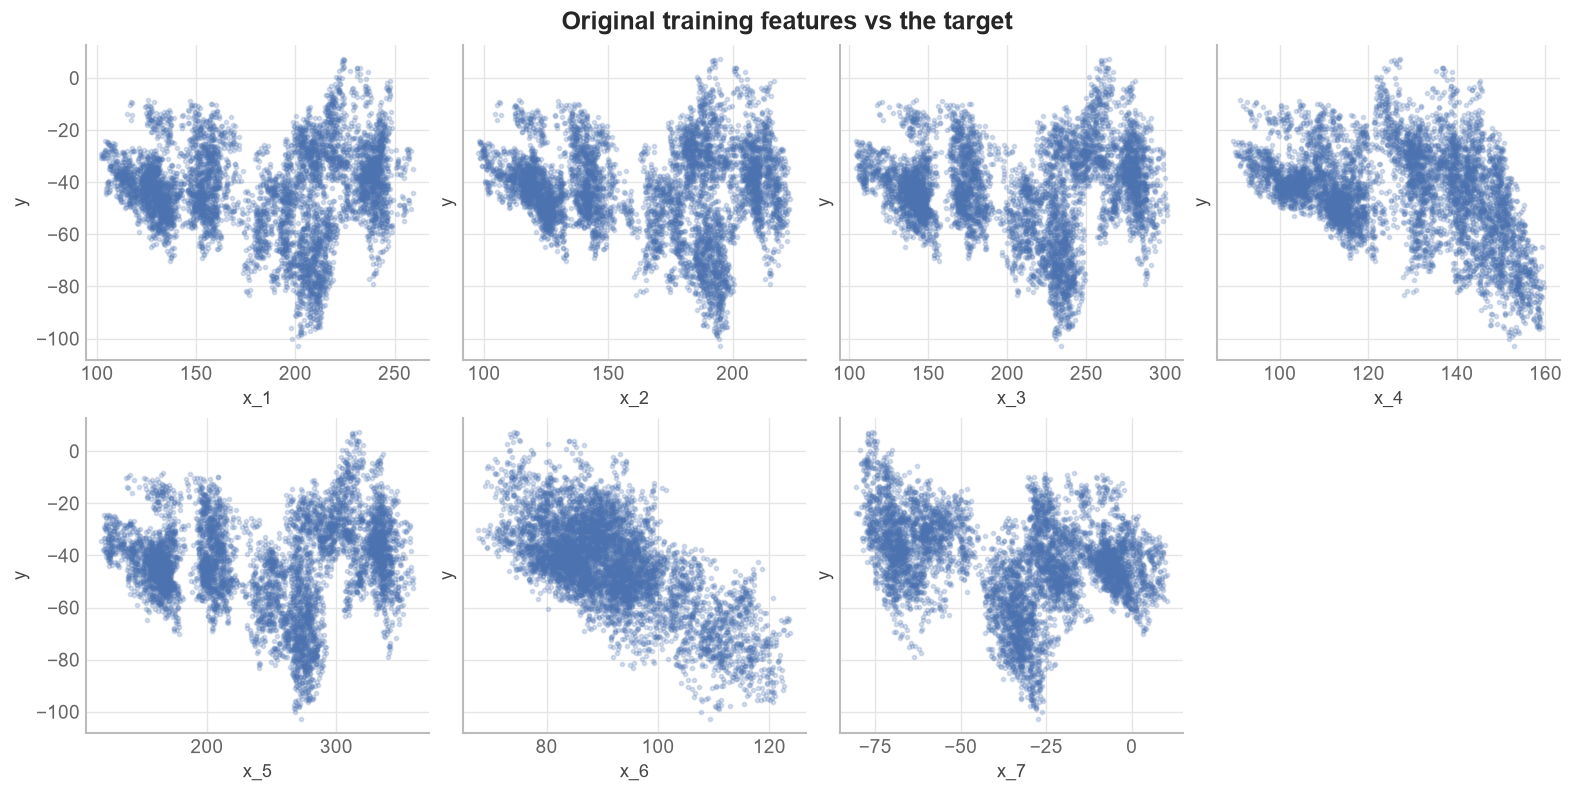

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6.5), sharey=True)
for ax, col in zip(axes.flat, features):
    ax.scatter(train[col], train["y"], alpha=0.22, s=6, rasterized=True)
    ax.set(xlabel=col, ylabel="y")
axes.flat[-1].axis("off")
fig.suptitle("Original training features vs the target", fontweight="bold")
plt.show()

Some of these features look more useful than others, however, I would be careful about drawing conclusions from these plots alone. A feature may not tell us much on its own, but could still be useful in combination with another feature.

To get a better idea of this, I would look at the correlations between the columns. These measure linear relationships, so they will not tell us everything either.

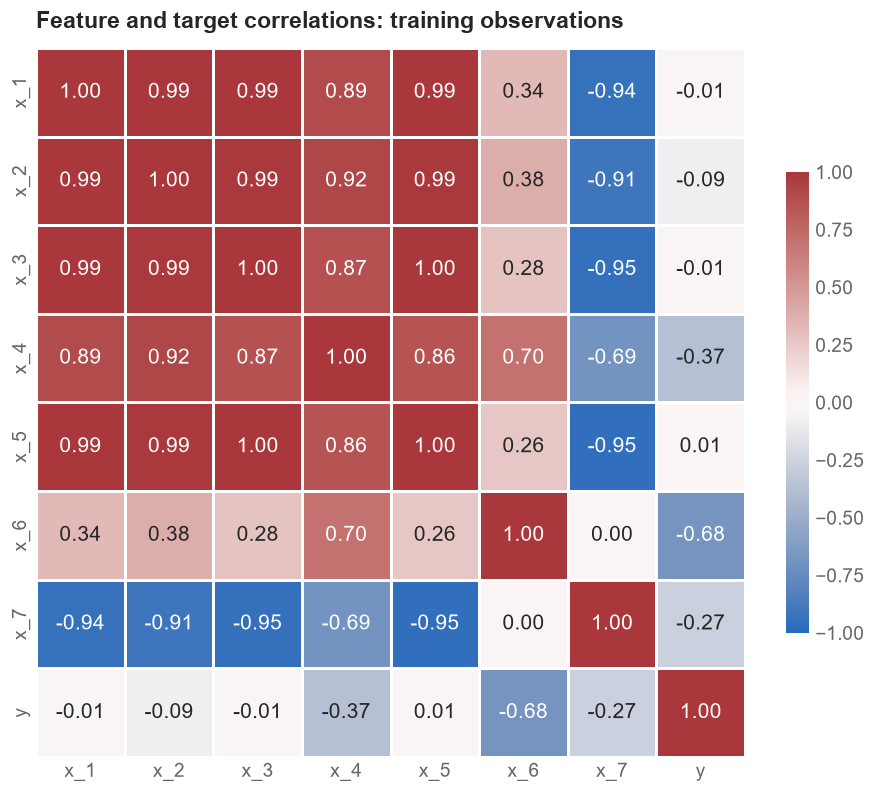

,Absolute correlation with y
x_6,0.684815
x_4,0.374056
x_7,0.266604
x_2,0.090891
x_1,0.014390
x_5,0.014213
x_3,0.006074


In [6]:
corr = train[features + ["y"]].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, cmap="vlag", vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", square=True, linewidths=0.8,
            linecolor="white", cbar_kws={"shrink": 0.65}, ax=ax)
ax.set_title("Feature and target correlations: training observations")
ax.grid(False)
plt.show()
display(corr.loc[features, "y"].abs().sort_values(ascending=False)
        .rename("Absolute correlation with y").to_frame())

Here we can see that `x_1`, `x_2`, `x_3`, and `x_5` are very highly correlated. This can cause problems if we fit our model by directly inverting the matrix in the normal equation. It also suggests that these features contain quite similar information.

However, that does not mean we should simply remove them. The difference between two features that move together could still tell us something about the target. We will come back to this after fitting a simple model.

### **2 - Does the order of the data matter?**

Given this data has no real-world labels or anything that tells us whether it follows a time series, I would also plot some of the columns against the row index. This lets us see whether neighbouring observations look related, which is something the scatterplots above do not tell us. Here I have chosen `x_1` from the correlated group, `x_6` from outside that group, and the target.

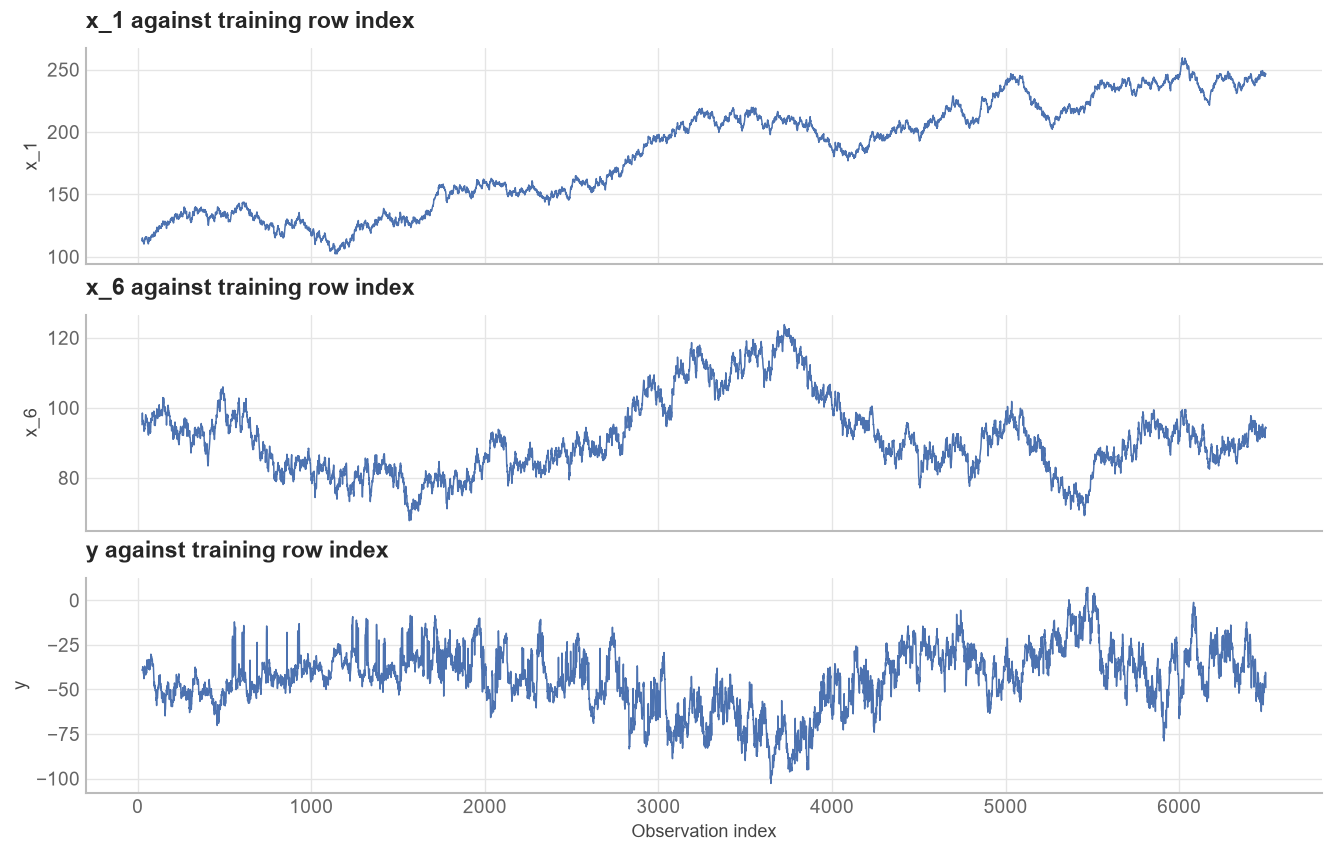

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, col in zip(axes, ["x_1", "x_6", "y"]):
    ax.plot(train.index, train[col], lw=0.9)
    ax.set(ylabel=col, title=f"{col} against training row index")
axes[-1].set_xlabel("Observation index")
plt.show()

Here the features change quite smoothly over long stretches of observations. The target also has some structure. This gives us a reason to investigate earlier observations, however, smooth inputs alone do not establish that a delayed input will help predict the target.

It also gives us a reason to be cautious about a random split, which could put very similar neighbouring observations in both training and validation. We will keep the ordered split we set aside earlier. If we eventually use delayed inputs, we will be assuming that the earlier feature values are available when making a prediction. We will not use earlier target values as inputs.

### **3 - Implementing a simple linear model**

Here I am starting with a linear regression class similar to the one from the exercise. There are two details I would like to point out.

First, I use `np.linalg.lstsq` to fit the parameters. This solves the least-squares problem without directly inverting $Z^TZ$, which is useful given how correlated some of our features are.

Second, I construct the basis functions before normalising the columns. Later we will add squares and products of features, and each of those new columns should be normalised too. The means and standard deviations are calculated from the training data and then reused when making predictions.

I will compare a model that always predicts the training mean, a model using `x_6`, one using `x_4` and `x_6`, and one using all seven features. The plot and correlation table give us a reason to start with `x_6`. Including `x_4` gives us a small model in which to investigate the two concentrations of values we saw earlier. These are starting comparisons, rather than a claim that we have found the best subset.

In [8]:
class Regression():
    def __init__(self):
        self.theta = None
        self.normalisation_means = None
        self.normalisation_stds = None
        self.eps = 1e-6  # Small constant to avoid division by zero

    def construct_design_matrix(self, X):
        X = np.asarray(X, dtype=float)
        # Add a column of ones for the intercept term
        return np.hstack((np.ones((X.shape[0], 1)), X))

    def normalise(self, X):
        # Only calculate the mean and std during fitting
        if self.normalisation_means is None or self.normalisation_stds is None:
            self.normalisation_means = X.mean(axis=0)
            self.normalisation_stds = X.std(axis=0)
        return (X - self.normalisation_means) / (self.normalisation_stds + self.eps)

    def _prepare(self, X):
        Z = self.construct_design_matrix(X)
        # The intercept is not normalised
        return np.column_stack((Z[:, 0], self.normalise(Z[:, 1:])))

    def fit(self, X, y):
        self.normalisation_means = None
        self.normalisation_stds = None
        Z = self._prepare(X)
        # Least squares is more stable than explicitly inverting Z.T @ Z
        self.theta = np.linalg.lstsq(Z, np.asarray(y), rcond=None)[0]
        return self

    def predict(self, X):
        if self.theta is None:
            raise ValueError("Fit the model before making predictions.")
        Z = self._prepare(X)
        return Z @ self.theta

In [9]:
results = []
fitted_models = {}

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def evaluate(name, model, X, record=True):
    model.fit(X[train_rows], y[train_rows])
    row = {"Model": name,
           "Train MSE": float(mse(y[train_rows], model.predict(X[train_rows]))),
           "Validation MSE": float(mse(y[valid_rows], model.predict(X[valid_rows])))}
    if record:
        results.append(row)
        fitted_models[name] = (model, X)
    print(f"{name}: train MSE = {row['Train MSE']:.3f}, "
          f"validation MSE = {row['Validation MSE']:.3f}")
    return model

mean_model = evaluate("Training mean", Regression(), np.empty((len(data), 0)))
model_x6 = evaluate("Linear: x_6", Regression(), data[["x_6"]].to_numpy())
model_two = evaluate("Linear: x_4, x_6", Regression(), data[["x_4", "x_6"]].to_numpy())
model_all = evaluate("Linear: all seven", Regression(), X_raw)
display(pd.DataFrame(results).round(3))

# Every diagnostic below uses training residuals, never test residuals.
def training_residuals(model, X):
    return y[train_rows] - model.predict(X[train_rows])

def binned_means(x, values, n_bins=20, min_count=20, limits=None):
    x, values = np.asarray(x), np.asarray(values)
    lo, hi = np.percentile(x, [1, 99]) if limits is None else limits
    edges = np.linspace(lo, hi, n_bins + 1)
    groups = np.digitize(x, edges)
    centres, averages, counts = [], [], []
    for j in range(1, len(edges)):
        mask = groups == j
        if mask.sum() >= min_count:
            centres.append(float(x[mask].mean()))
            averages.append(float(values[mask].mean()))
            counts.append(int(mask.sum()))
    return np.array(centres), np.array(averages), np.array(counts)

Training mean: train MSE = 296.909, validation MSE = 180.653
Linear: x_6: train MSE = 157.667, validation MSE = 124.507
Linear: x_4, x_6: train MSE = 150.918, validation MSE = 116.780
Linear: all seven: train MSE = 55.713, validation MSE = 57.470


,Model,Train MSE,Validation MSE
0,Training mean,296.909,180.653
1,Linear: x_6,157.667,124.507
2,"Linear: x_4, x_6",150.918,116.780
3,Linear: all seven,55.713,57.470


### **3a - Trying nonlinear functions of `x_4`**

The two concentrations in `x_4` describe where the inputs are, however, that alone does not tell us that its relationship with the target is nonlinear. I would first look at what the small linear model has left unexplained. The line below groups similar values of `x_4` and shows the average residual in each group. This makes broad trends easier to see than the individual points, although it can hide variation within a group.

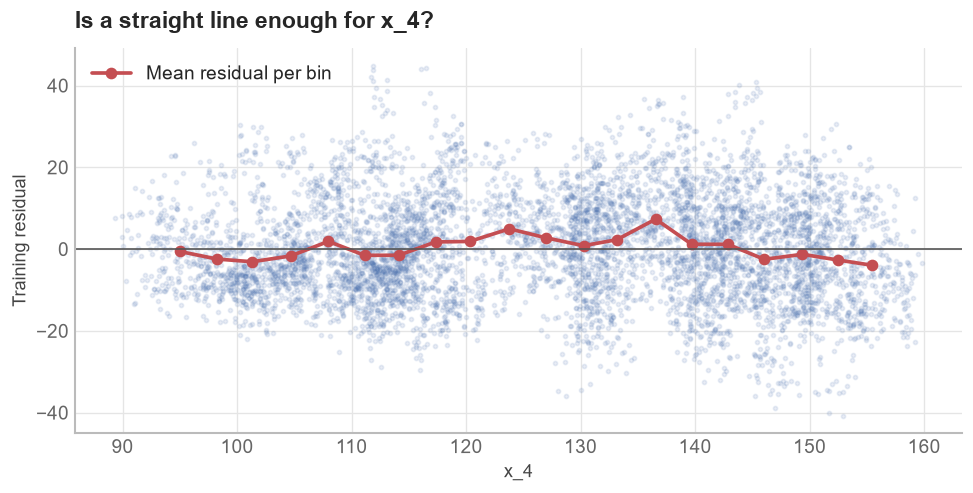

In [10]:
X_two = data[["x_4", "x_6"]].to_numpy()
residual_two = training_residuals(model_two, X_two)
cx, cy, _ = binned_means(train["x_4"], residual_two)
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(train["x_4"], residual_two, s=6, alpha=0.12, rasterized=True)
ax.plot(cx, cy, color=palette[3], marker="o", label="Mean residual per bin")
ax.axhline(0, color="#555555", lw=1)
ax.set(xlabel="x_4", ylabel="Training residual", title="Is a straight line enough for x_4?")
ax.legend()
plt.show()

A residual trend gives us a reason to try a more flexible function, but does not identify one particular formula. I will compare a squared term with five Gaussian radial basis functions (RBFs), keeping `x_4` and `x_6` as linear inputs. These are two simple alternatives from the basis-function idea in the exercise.

Each RBF is largest near a particular value of `x_4` and gets smaller further away. I place five centres at training quantiles so that they cover the observed values. I use the median spacing between the centres as the width, so neighbouring functions overlap. Five functions is a modest initial choice, not an optimum we have established. We could compare other widths and numbers of centres if this family looked promising.

In [11]:
class RegressionQuadratic(Regression):
    def construct_design_matrix(self, X):
        X = np.asarray(X, dtype=float)
        return np.column_stack((np.ones(len(X)), X, X[:, 0] ** 2))

class RegressionRBF(Regression):
    def __init__(self, centres, width):
        super().__init__()
        self.centres = np.asarray(centres)
        self.width = width

    def construct_design_matrix(self, X):
        X = np.asarray(X, dtype=float)
        rbf = np.exp(-0.5 * ((X[:, [0]] - self.centres) / self.width) ** 2)
        return np.column_stack((np.ones(len(X)), X, rbf))

rbf_centres = np.quantile(X_two[train_rows, 0], [0.1, 0.3, 0.5, 0.7, 0.9])
rbf_width = max(float(np.median(np.diff(rbf_centres))), 1e-6)
print(f"Training-derived RBF width: {rbf_width:.3f}")
m_quad = evaluate("Quadratic: x_4 and x_6", RegressionQuadratic(), X_two)
m_rbf = evaluate("RBF: x_4 and x_6", RegressionRBF(rbf_centres, rbf_width), X_two)
display(pd.DataFrame(results).round(3))

Training-derived RBF width: 11.005
Quadratic: x_4 and x_6: train MSE = 147.609, validation MSE = 114.644
RBF: x_4 and x_6: train MSE = 145.297, validation MSE = 113.296


,Model,Train MSE,Validation MSE
0,Training mean,296.909,180.653
1,Linear: x_6,157.667,124.507
2,"Linear: x_4, x_6",150.918,116.780
3,Linear: all seven,55.713,57.470
4,Quadratic: x_4 and x_6,147.609,114.644
5,RBF: x_4 and x_6,145.297,113.296


Here I would compare the nonlinear models with the linear model using the same two inputs, and then with the model using all seven. The first comparison tells us whether the extra functions help this small model. The second tells us whether we are leaving useful information out by concentrating on these two inputs.

Before trying more complicated functions of `x_4`, I would go back to the correlated features and look at them together.

### **4 - Looking at features together**

Before choosing particular differences, I would look at all the pairs in the highly correlated group. Here I use an absolute training correlation of at least 0.98 as a display cutoff. This picks out all six pairs between `x_1`, `x_2`, `x_3`, and `x_5`, rather than selecting just `x_1` with `x_2` and `x_3` with `x_5` in advance. The cutoff is a way of keeping this figure focused on very similar inputs, not a test of whether the other features matter.

Below I have plotted each pair of training features against each other and coloured the points by the target. I would look for whether the colour changes across the narrow band of points. If it does, the small differences between the features may deserve a closer look.

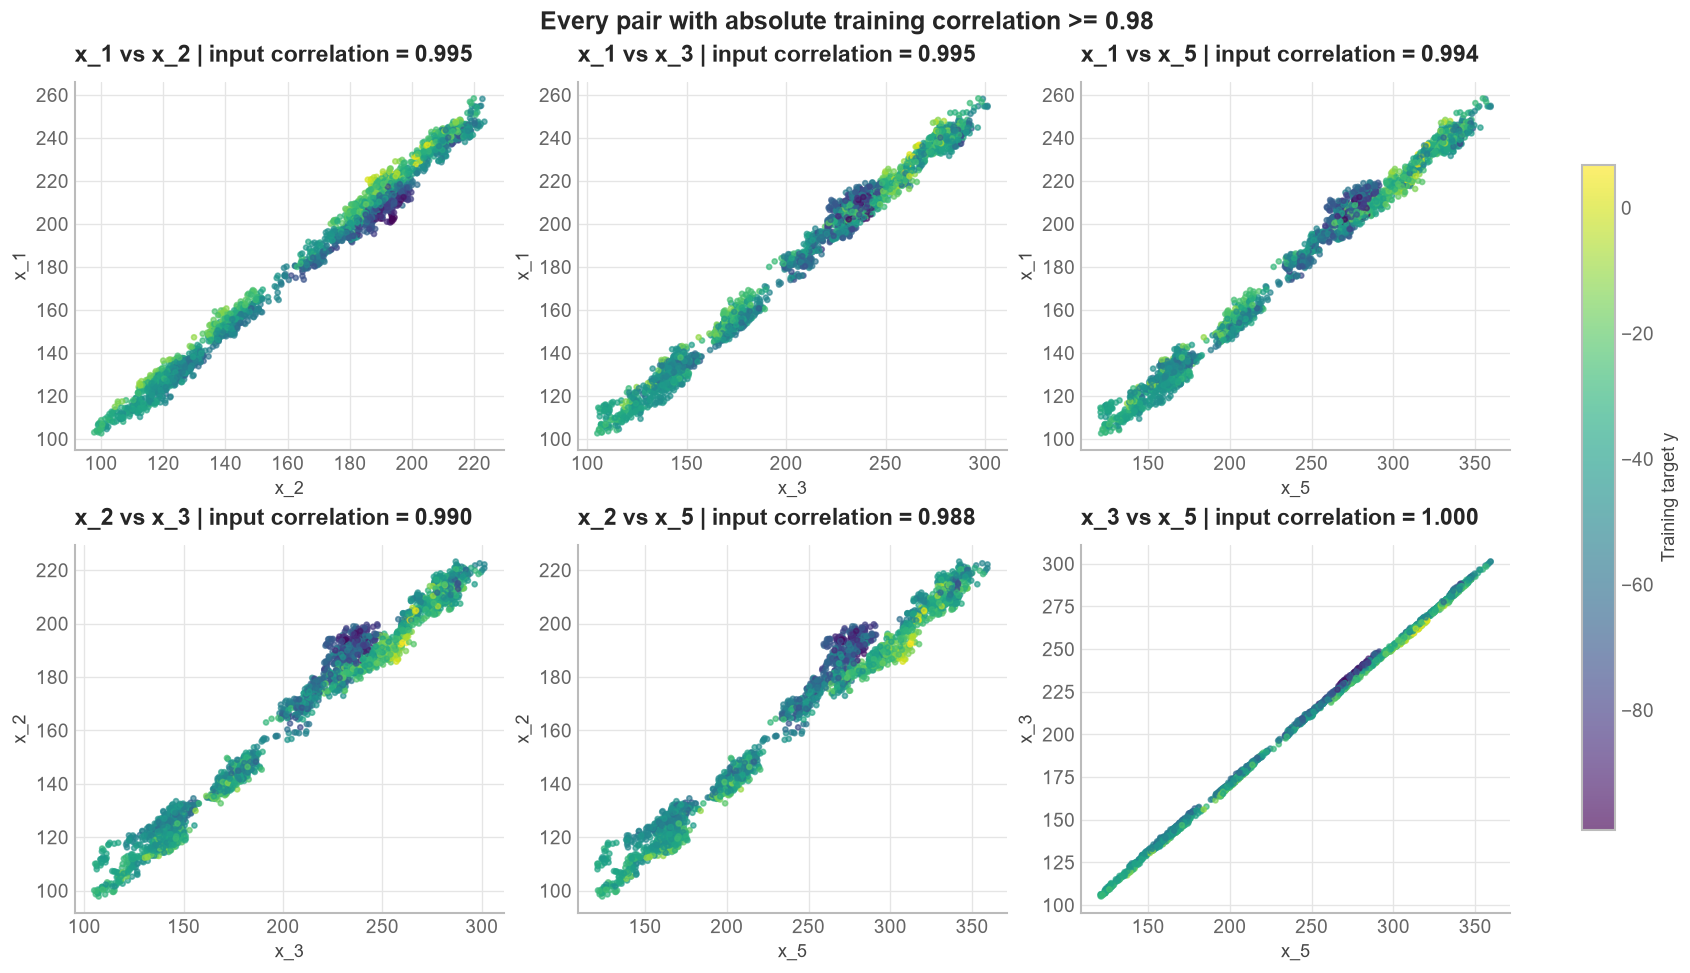

In [12]:
from itertools import combinations

high_correlation_cutoff = 0.98
correlated_pairs = [
    (a, b) for a, b in combinations(features, 2)
    if abs(corr.loc[a, b]) >= high_correlation_cutoff
]
assert len(correlated_pairs) > 0
sample = train.sample(n=min(2500, len(train)), random_state=42)
pair_plot_rows = int(np.ceil(len(correlated_pairs) / 3))
fig, axes = plt.subplots(pair_plot_rows, 3, figsize=(14, 4 * pair_plot_rows), squeeze=False)
for ax, (a, b) in zip(axes.flat, correlated_pairs):
    sc = ax.scatter(sample[b], sample[a], c=sample["y"], cmap="viridis",
                    s=9, alpha=0.65, rasterized=True)
    ax.set(xlabel=b, ylabel=a,
           title=f"{a} vs {b} | input correlation = {corr.loc[a, b]:.3f}")
for ax in axes.flat[len(correlated_pairs):]:
    ax.axis("off")
fig.colorbar(sc, ax=list(axes.flat[:len(correlated_pairs)]), label="Training target y", shrink=0.8)
fig.suptitle("Every pair with absolute training correlation >= 0.98", fontweight="bold")
plt.show()

To look more closely at these differences, we can subtract a scaled version of one feature from the other:

$$d_{a,b}=x_a-cx_b.$$

We need to choose a reference scale because the features have different magnitudes. Here I use the same rule for every pair: the ratio of their training means, rounded to two decimal places. This aligns their means approximately. It is a simple proportional reference, not a fitted relationship or a claim about how the data was generated. It would be unsuitable if the denominator mean were near zero.

A line fitted between the inputs would be another reasonable reference, and would also allow an intercept. I show its slope below so we can see that the choices need not agree. I am rounding only to start with an easy-to-read reference. We will check the two scales used by our later models, rather than treating these rounded numbers as known constants.

The next figure shows all six scaled differences against the training target, with the same target axis and the same plotting choices. The red line shows the mean target in bins of the difference. The horizontal axes have different units and ranges, so I would compare the shapes rather than their apparent slopes. Each title reports the correlation between the two original inputs, not the correlation of their difference with the target. We show each unordered pair once, using the feature order in the data.

,Pair,Input correlation,Ratio of means,Fitted slope,Initial scale
0,"x_1, x_2",0.9950,1.1025,1.2172,1.10
1,"x_1, x_3",0.9948,0.8818,0.7973,0.88
2,"x_1, x_5",0.9945,0.7484,0.6493,0.75
3,"x_2, x_3",0.9897,0.7998,0.6484,0.80
4,"x_2, x_5",0.9878,0.6788,0.5272,0.68
5,"x_3, x_5",0.9997,0.8488,0.8143,0.85


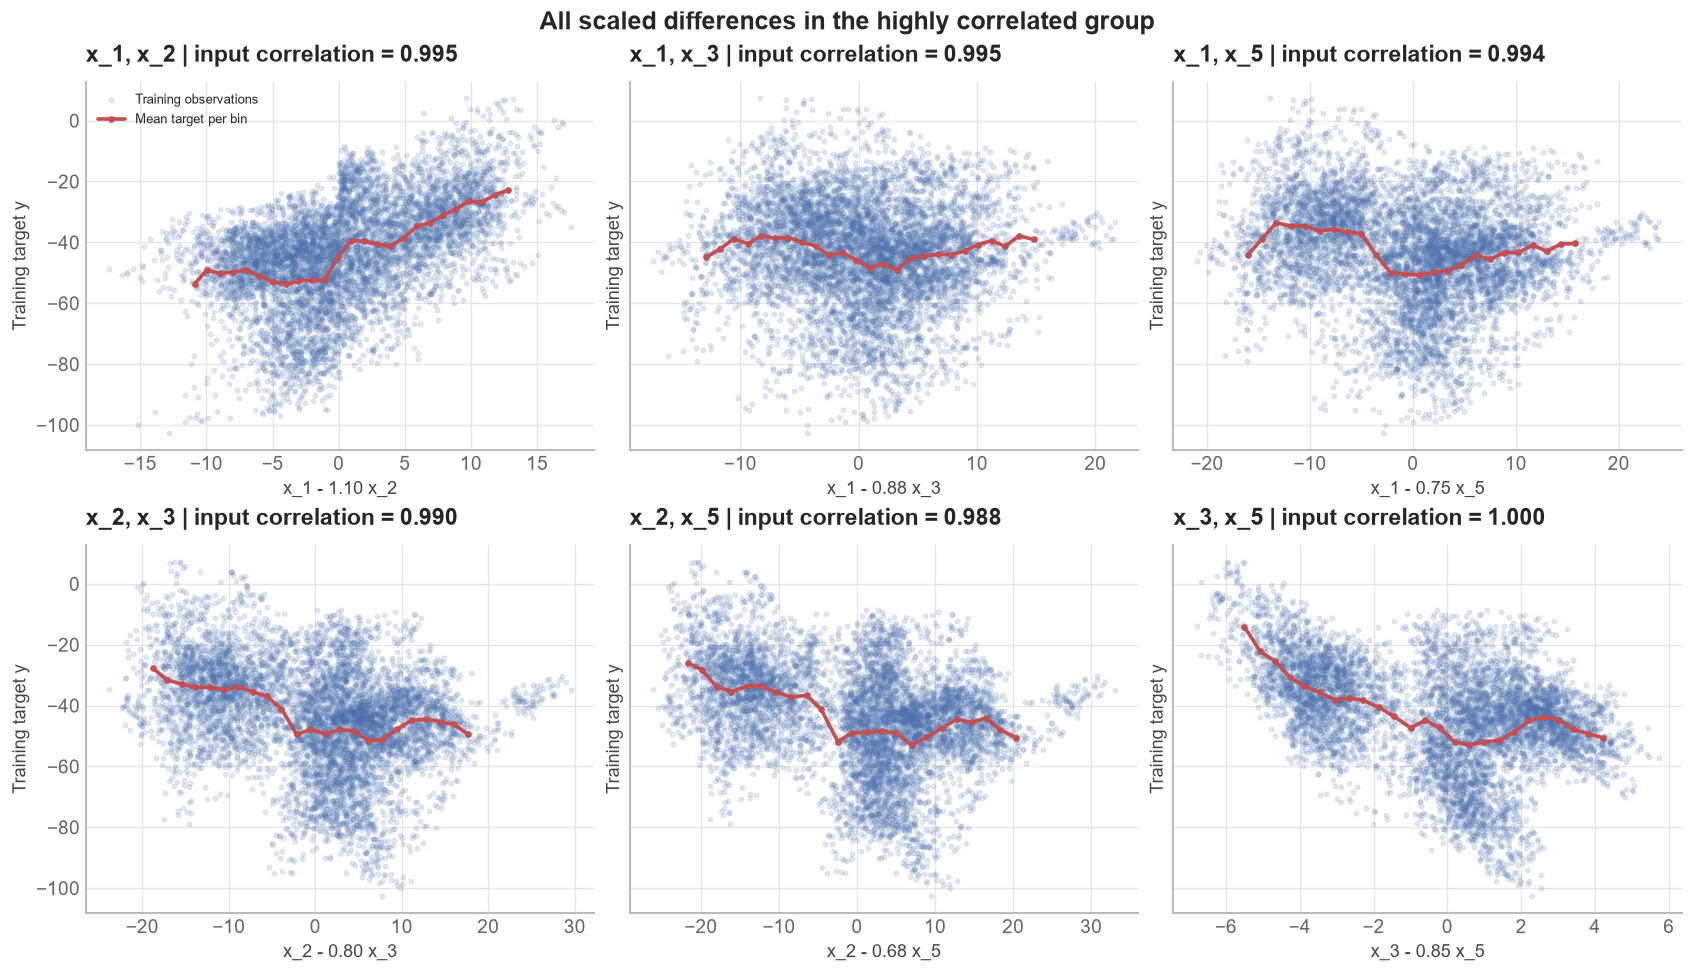

In [13]:
scale_rows = []
difference_scales = {}
for a, b in correlated_pairs:
    assert abs(train[b].mean()) > 1e-6
    mean_ratio = float(train[a].mean() / train[b].mean())
    fitted_slope = float(np.polyfit(train[b], train[a], 1)[0])
    difference_scales[(a, b)] = round(mean_ratio, 2)
    scale_rows.append({"Pair": f"{a}, {b}", "Input correlation": float(corr.loc[a, b]),
                       "Ratio of means": mean_ratio, "Fitted slope": fitted_slope,
                       "Initial scale": difference_scales[(a, b)]})
display(pd.DataFrame(scale_rows).round(4))

fig, axes = plt.subplots(pair_plot_rows, 3, figsize=(14, 4 * pair_plot_rows),
                         sharey=True, squeeze=False)
for ax, (a, b) in zip(axes.flat, correlated_pairs):
    scale = difference_scales[(a, b)]
    difference = (train[a] - scale * train[b]).to_numpy()
    ax.scatter(difference, train["y"], alpha=0.14, s=7, rasterized=True,
               label="Training observations")
    bin_x, bin_y, _ = binned_means(difference, train["y"], n_bins=25)
    ax.plot(bin_x, bin_y, color=palette[3], marker="o", ms=3,
            label="Mean target per bin")
    ax.set(xlabel=f"{a} - {scale:.2f} {b}", ylabel="Training target y",
           title=f"{a}, {b} | input correlation = {corr.loc[a, b]:.3f}")
for ax in axes.flat[len(correlated_pairs):]:
    ax.axis("off")
axes.flat[0].legend(fontsize=8)
fig.suptitle("All scaled differences in the highly correlated group", fontweight="bold")
plt.show()

# Keep two reference coordinates for the experiments that follow.
ratio_12 = difference_scales[("x_1", "x_2")]
ratio_35 = difference_scales[("x_3", "x_5")]
initial_ratio_12, initial_ratio_35 = ratio_12, ratio_35
d12 = data["x_1"] - ratio_12 * data["x_2"]
d35 = data["x_3"] - ratio_35 * data["x_5"]
d12_train = d12.iloc[train_rows].to_numpy()
d35_train = d35.iloc[train_rows].to_numpy()

These comparisons give us several possible differences to investigate, not two uniquely correct ones. In the `x_1`/`x_2` panel, the mean target changes near zero and then rises on the positive side. In the `x_3`/`x_5` panel, we can see a target trend across a small difference between inputs that almost lie on a straight line. I will keep these as two reference coordinates for the following experiments. These observations give us reasons to investigate them, but the figure does not establish that they are the best pair of differences. The other pairs remain possible alternatives; choosing the best subset would require comparing their basis functions using validation data too.

Adding either difference on its own would not give our linear model anything new, because it already contains the original columns. We need to ask whether the differences enter in some other way.

I would first return to the residuals from the all-seven model. The first plot below shows their average against the first difference. In the next two plots, I split `x_4` and `x_6` into training quartiles and draw a separate residual trend against the second difference for each group. If those trends have different slopes, a product is one simple way to let the effect of the difference depend on another feature. The plots can suggest this experiment, however, other correlated inputs may also explain the pattern.

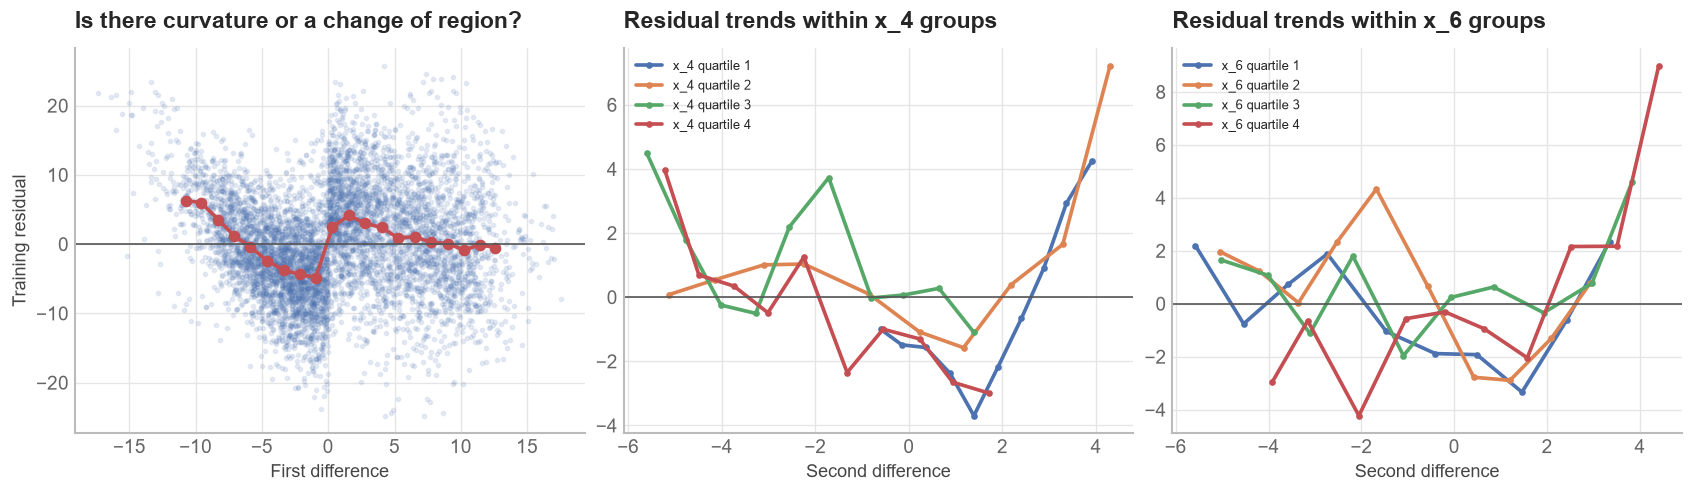

In [14]:
residual_all = training_residuals(model_all, X_raw)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].scatter(d12_train, residual_all, alpha=0.12, s=6, rasterized=True)
bx, by, _ = binned_means(d12_train, residual_all)
axes[0].plot(bx, by, color=palette[3], marker="o")
axes[0].set(xlabel="First difference", ylabel="Training residual", title="Is there curvature or a change of region?")
for ax, feature in zip(axes[1:], ["x_4", "x_6"]):
    groups = pd.qcut(train[feature], 4, labels=False).to_numpy()
    for group in range(4):
        mask = groups == group
        bx, by, _ = binned_means(d35_train[mask], residual_all[mask], n_bins=10)
        ax.plot(bx, by, marker="o", ms=3, label=f"{feature} quartile {group + 1}")
    ax.set(xlabel="Second difference", title=f"Residual trends within {feature} groups")
    ax.legend(fontsize=8)
for ax in axes:
    ax.axhline(0, color="#555555", lw=1)
plt.show()

### **5 - Testing squares and products separately**

A squared first difference is a simple way to try curvature. Products of the second difference with `x_4` and `x_6` let its contribution change with those inputs. Neither is implied uniquely by the plots, so I will compare the square alone, the products alone, and both together against the all-seven baseline.

Here I have kept the feature construction inside `construct_design_matrix`, as in the exercise. Each function in `terms` supplies extra columns. We can add a new experiment when we reach it, without including formulas for later discoveries in the class now.

In [15]:
class FeatureRegression(Regression):
    def __init__(self, terms=()):
        super().__init__()
        self.terms = list(terms)

    def construct_design_matrix(self, X):
        X = np.asarray(X, dtype=float)
        columns = [np.ones(len(X)), X[:, :7]]
        columns.extend(term(X) for term in self.terms)
        return np.column_stack(columns)

def squared_difference(scale):
    def term(X):
        return (X[:, 0] - scale * X[:, 1]) ** 2
    return term

def current_interactions(scale):
    def term(X):
        difference = X[:, 2] - scale * X[:, 4]
        return difference[:, None] * X[:, [3, 5]]
    return term

square_term = squared_difference(ratio_12)
interaction_term = current_interactions(ratio_35)
m_sq = evaluate("All seven + square", FeatureRegression([square_term]), X_raw)
m_products = evaluate("All seven + current products", FeatureRegression([interaction_term]), X_raw)
m_inter = evaluate("All seven + square + current products",
                   FeatureRegression([square_term, interaction_term]), X_raw)
# Keep the initial scale available to the existing chart-data exporter.
m_inter.ratio_35 = initial_ratio_35
display(pd.DataFrame(results).round(3))

All seven + square: train MSE = 54.692, validation MSE = 60.263
All seven + current products: train MSE = 53.359, validation MSE = 54.745
All seven + square + current products: train MSE = 53.189, validation MSE = 56.045


,Model,Train MSE,Validation MSE
0,Training mean,296.909,180.653
1,Linear: x_6,157.667,124.507
2,"Linear: x_4, x_6",150.918,116.780
3,Linear: all seven,55.713,57.470
4,Quadratic: x_4 and x_6,147.609,114.644
5,RBF: x_4 and x_6,145.297,113.296
6,All seven + square,54.692,60.263
7,All seven + current products,53.359,54.745
8,All seven + square + current products,53.189,56.045


Here I would look at validation error, rather than the reduction in training error. If an addition makes validation error worse, we have not earned a reason to keep it in the selected model.

However, a feature that is unhelpful on its own can sometimes become useful alongside another change. I will keep the square-and-products model as an exploratory branch when we investigate delays. We will compare it with simpler branches, and check whether its individual terms are still useful later. This is a reason to continue an experiment, rather than evidence that its current validation result is better.

### **6 - Investigating delayed relationships**

The row-index plots gave us a reason to investigate earlier inputs, but did not identify a particular delay or a particular product. I will therefore compare two experiments over the same range: adding an earlier second difference on its own, and adding its products with the current `x_4` and `x_6` to our exploratory branch.

A delay of zero uses the current row. In the product branch it duplicates columns already present, so it provides no new information. Positive delays use earlier feature rows only. I will try every delay from zero to our initial budget of 25 and show the full validation curves. An optimum at the end of the range would be a reason to investigate a wider range before settling on a delay.

#### **What does a delay change in the matrix?**

A delay adds columns to the inputs. It does not move the target or replace the current observation with an earlier one. I will use $t$ to mean the original row index, rather than a timestamp, and $\ell$ for the number of rows earlier.

For one observation, `make_inputs(lag)` constructs this row. The first seven entries come from the current row; only the final two entries come from an earlier row:

$$
X^{\mathrm{input}}_t = \left[
\underbrace{x_{1,t},\ldots,x_{7,t}}_{\text{current row }t}
\;\middle|\;
\underbrace{x_{3,t-\ell},x_{5,t-\ell}}_{\text{earlier row }t-\ell}
\right].
$$

For a delay of two, a few rows of that input matrix line up with the target as follows. The vertical line separates current columns from the two appended columns:

$$
X^{\mathrm{input}} =
\left[\begin{array}{ccc|cc}
x_{1,2} & \cdots & x_{7,2} & x_{3,0} & x_{5,0} \\
x_{1,3} & \cdots & x_{7,3} & x_{3,1} & x_{5,1} \\
x_{1,4} & \cdots & x_{7,4} & x_{3,2} & x_{5,2} \\
\vdots & & \vdots & \vdots & \vdots
\end{array}\right],
\qquad
y = \begin{bmatrix} y_2 \\ y_3 \\ y_4 \\ \vdots \end{bmatrix}.
$$

Each row still predicts its own target. For example, the second displayed row combines current inputs from row 3 with the selected inputs from row 1, and predicts $y_3$.

There is one other distinction here: this nine-column input matrix is what we pass to the model. `construct_design_matrix` then builds the columns that receive fitted coefficients. It does not automatically give the two earlier raw inputs their own coefficients.

If we write $d_t=x_{3,t}-c x_{5,t}$ and $q_t=x_{1,t}-a x_{2,t}$, the simpler delayed model adds just $d_{t-\ell}$ to its design matrix. Our product branch instead constructs this row of the design matrix:

$$
Z_t = \left[
\underbrace{1}_{\text{intercept}},\;
\underbrace{x_{1,t},\ldots,x_{7,t}}_{\text{7 current inputs}},\;
\underbrace{q_t^2,\;d_t x_{4,t},\;d_t x_{6,t}}_{\text{3 current basis functions}}
\;\middle|\;
\underbrace{d_{t-\ell}x_{4,t},\;d_{t-\ell}x_{6,t}}_{\text{2 delayed interaction columns}}
\right].
$$

This gives us 13 columns: one intercept, seven original features, three current basis functions, and two delayed interactions. In the last two columns, the difference is earlier but `x_4` and `x_6` are current. We are testing whether an earlier difference changes the contribution of these current inputs.

We construct these columns first, then normalise each non-intercept column using training statistics, as before. The delay is a choice about where the values in a column come from. We still fit $\hat y=Z\theta$ using least squares.

In [16]:
def make_inputs(lag=0):
    assert 0 <= lag <= max_lag
    return np.column_stack([X_raw,
                            data["x_3"].shift(lag).to_numpy(),
                            data["x_5"].shift(lag).to_numpy()])

def delayed_difference(scale):
    def term(X):
        return X[:, 7] - scale * X[:, 8]
    return term

def delayed_interactions(scale):
    def term(X):
        difference = X[:, 7] - scale * X[:, 8]
        return difference[:, None] * X[:, [3, 5]]
    return term

#### **Following one row through a delay of two**

Here I have made a small example with invented numbers, so that we can follow the movement of the values. The first table shows only the current features involved in the delayed terms. Blue cells are current inputs, orange cells use earlier inputs, and green cells are the target from the current row.

For row 3 and a delay of two, we take `x_3 = 20` and `x_5 = 2` from row 1. With an example scale of $c=2$, their difference is $20-2\times2=16$. We multiply that earlier difference by the current row's `x_4 = 5` and `x_6 = 4`, giving the two new entries $80$ and $64$. The target stays at $y_3=130$.

The lower table shows the design matrix after constructing these columns. To keep it readable, I have grouped the seven original columns into one block. Each of the other feature columns shown receives its own coefficient. The target is alongside the matrix for alignment; it is not an input column.

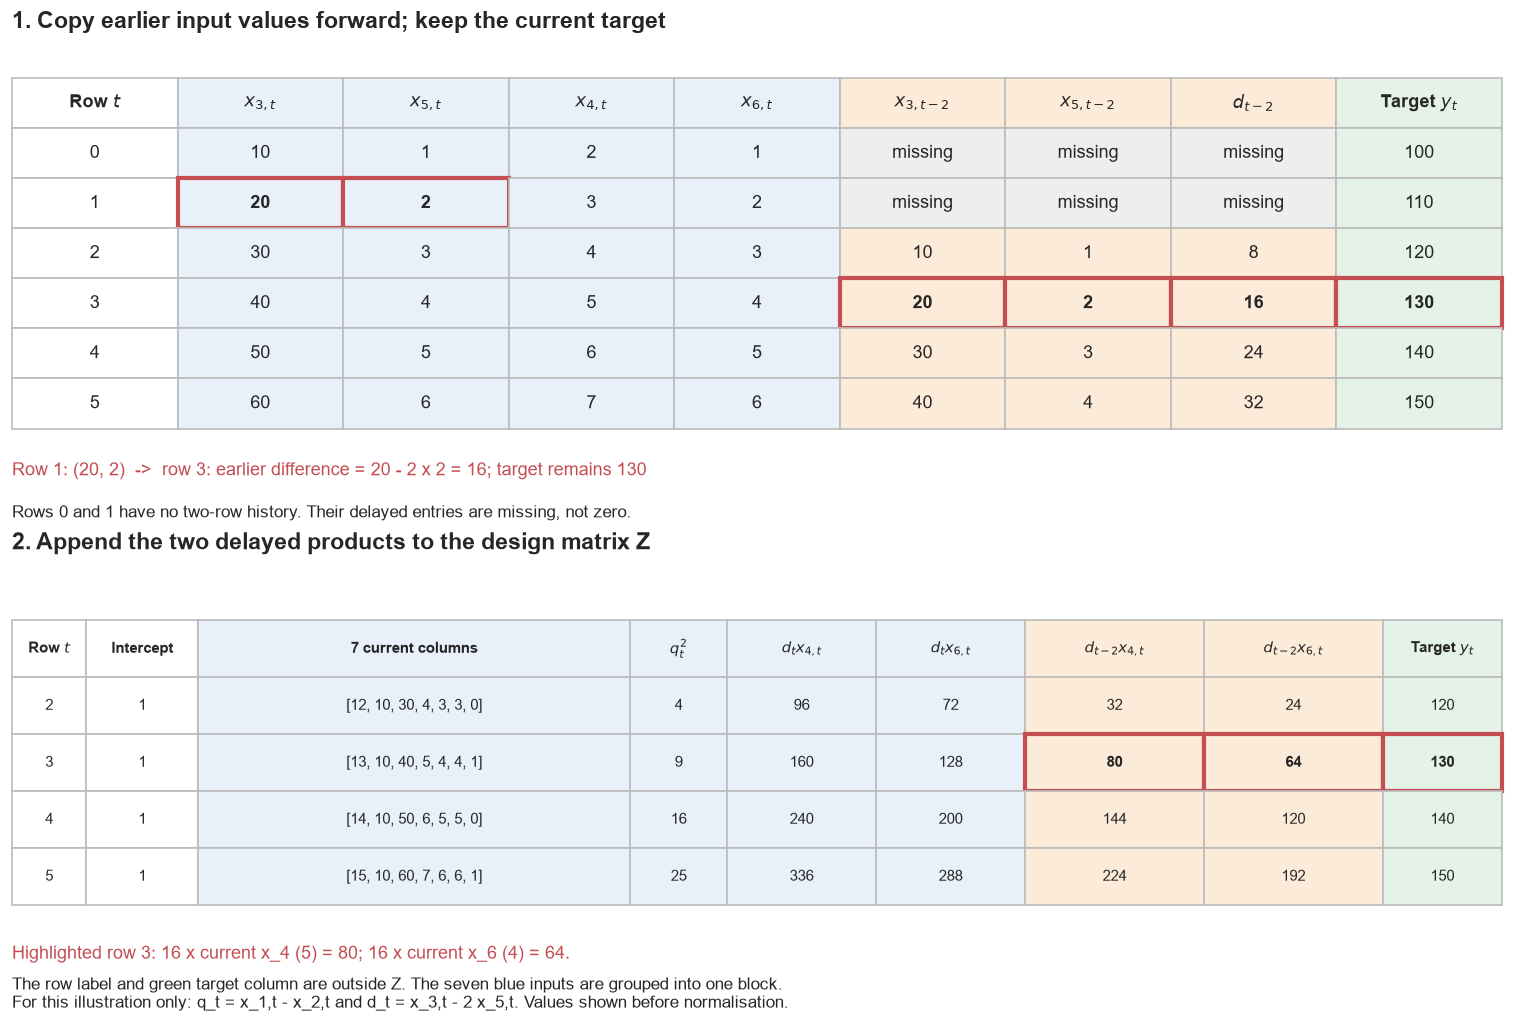

In [17]:
# Invented values for illustration only; no model is fitted to this table.
delay_demo_lag = 2
delay_demo_scale = 2.0
delay_demo = pd.DataFrame({
    "x_1": [10, 11, 12, 13, 14, 15],
    "x_2": [10, 10, 10, 10, 10, 10],
    "x_3": [10, 20, 30, 40, 50, 60],
    "x_4": [2, 3, 4, 5, 6, 7],
    "x_5": [1, 2, 3, 4, 5, 6],
    "x_6": [1, 2, 3, 4, 5, 6],
    "x_7": [0, 1, 0, 1, 0, 1],
    "y": [100, 110, 120, 130, 140, 150],
})
delay_demo_inputs = np.column_stack([
    delay_demo[features].to_numpy(),
    delay_demo["x_3"].shift(delay_demo_lag).to_numpy(),
    delay_demo["x_5"].shift(delay_demo_lag).to_numpy(),
])
delay_demo_difference = delayed_difference(delay_demo_scale)(delay_demo_inputs)
delay_demo_model = FeatureRegression([
    squared_difference(1.0), current_interactions(delay_demo_scale),
    delayed_interactions(delay_demo_scale),
])
# Use the actual design-matrix method, before column normalisation.
delay_demo_Z = delay_demo_model.construct_design_matrix(delay_demo_inputs)
assert delay_demo_Z.shape == (6, 13)
assert np.array_equal(delay_demo_Z[3, -2:], [80, 64])
assert np.isnan(delay_demo_Z[:delay_demo_lag, -2:]).all()
assert np.isfinite(delay_demo_Z[delay_demo_lag:]).all()

delay_demo_blue = "#E8F0FA"
delay_demo_orange = "#FCEBD8"
delay_demo_green = "#E4F2E7"
delay_demo_grey = "#EEEEEE"
delay_demo_highlight = "#C44E52"

def delay_demo_number(value):
    return "missing" if np.isnan(value) else f"{value:g}"

delay_demo_top_rows = []
for t in delay_demo.index:
    delay_demo_top_rows.append([
        str(t), *[str(delay_demo.loc[t, col]) for col in ["x_3", "x_5", "x_4", "x_6"]],
        delay_demo_number(delay_demo_inputs[t, 7]),
        delay_demo_number(delay_demo_inputs[t, 8]),
        delay_demo_number(delay_demo_difference[t]), str(delay_demo.loc[t, "y"]),
    ])

delay_demo_fig, delay_demo_axes = plt.subplots(2, 1, figsize=(12.5, 8.5),
                                              gridspec_kw={"height_ratios": [1.05, 1]})
for ax in delay_demo_axes:
    ax.axis("off")
delay_demo_axes[0].set_title("1. Copy earlier input values forward; keep the current target", pad=16)
delay_demo_top = delay_demo_axes[0].table(
    cellText=delay_demo_top_rows,
    colLabels=[r"Row $t$", r"$x_{3,t}$", r"$x_{5,t}$", r"$x_{4,t}$", r"$x_{6,t}$",
               r"$x_{3,t-2}$", r"$x_{5,t-2}$", r"$d_{t-2}$", r"Target $y_t$"],
    cellLoc="center", loc="center", bbox=[0, 0.20, 1, 0.75],
)
delay_demo_top.auto_set_font_size(False)
delay_demo_top.set_fontsize(11)
for (row, col), entry in delay_demo_top.get_celld().items():
    colour = (delay_demo_blue if 1 <= col <= 4 else delay_demo_orange if 5 <= col <= 7
              else delay_demo_green if col == 8 else "white")
    if row in (1, 2) and 5 <= col <= 7:
        colour = delay_demo_grey
    entry.set_facecolor(colour)
    entry.set_edgecolor("#BBBBBB")
    if row == 0:
        entry.set_text_props(weight="bold")
    # Source values in row 1 -> copied values in row 3; target stays row 3.
    if (row == 2 and col in (1, 2)) or (row == 4 and col in (5, 6, 7, 8)):
        entry.set_edgecolor(delay_demo_highlight)
        entry.set_linewidth(2.5)
        entry.set_text_props(weight="bold")
delay_demo_axes[0].text(0, 0.10,
    "Row 1: (20, 2)  ->  row 3: earlier difference = 20 - 2 x 2 = 16; target remains 130",
    transform=delay_demo_axes[0].transAxes, fontsize=11, color=delay_demo_highlight)
delay_demo_axes[0].text(0, 0.01,
    "Rows 0 and 1 have no two-row history. Their delayed entries are missing, not zero.",
    transform=delay_demo_axes[0].transAxes, fontsize=10)

delay_demo_bottom_rows = []
for t in range(delay_demo_lag, len(delay_demo)):
    # Group columns 1:8 visually; keep every constructed value unchanged.
    delay_demo_bottom_rows.append([
        str(t), "1", "[" + ", ".join(f"{v:g}" for v in delay_demo_Z[t, 1:8]) + "]",
        *[f"{v:g}" for v in delay_demo_Z[t, 8:]], str(delay_demo.loc[t, "y"]),
    ])
delay_demo_axes[1].set_title("2. Append the two delayed products to the design matrix Z", pad=16)
delay_demo_bottom = delay_demo_axes[1].table(
    cellText=delay_demo_bottom_rows,
    colLabels=[r"Row $t$", "Intercept", "7 current columns",
               r"$q_t^2$", r"$d_t x_{4,t}$", r"$d_t x_{6,t}$",
               r"$d_{t-2}x_{4,t}$", r"$d_{t-2}x_{6,t}$", r"Target $y_t$"],
    colWidths=[0.05, 0.075, 0.29, 0.065, 0.10, 0.10, 0.12, 0.12, 0.08],
    cellLoc="center", loc="center", bbox=[0, 0.26, 1, 0.64],
)
delay_demo_bottom.auto_set_font_size(False)
delay_demo_bottom.set_fontsize(9)
for (row, col), entry in delay_demo_bottom.get_celld().items():
    entry.set_facecolor(delay_demo_orange if col in (6, 7) else delay_demo_green if col == 8
                        else delay_demo_blue if 2 <= col <= 5 else "white")
    entry.set_edgecolor("#BBBBBB")
    if row == 0:
        entry.set_text_props(weight="bold")
    if row == 2 and col in (6, 7, 8):
        entry.set_edgecolor(delay_demo_highlight)
        entry.set_linewidth(2.5)
        entry.set_text_props(weight="bold")
delay_demo_axes[1].text(0, 0.14,
    "Highlighted row 3: 16 x current x_4 (5) = 80; 16 x current x_6 (4) = 64.",
    transform=delay_demo_axes[1].transAxes, fontsize=11, color=delay_demo_highlight)
delay_demo_axes[1].text(0, 0.03,
    "The row label and green target column are outside Z. The seven blue inputs are grouped into one block.\n"
    "For this illustration only: q_t = x_1,t - x_2,t and d_t = x_3,t - 2 x_5,t. Values shown before normalisation.",
    transform=delay_demo_axes[1].transAxes, fontsize=10)
plt.show()

In the code, a positive `shift(2)` puts the value from row $t-2$ alongside row $t$. It leaves the first two entries missing because those rows have no earlier observations in this dataset. We should omit those rows from fitting, rather than fill the missing history with zeros. In our full experiment we already start every comparison at row 25, so every candidate delay up to 25 has enough history on the same training and validation rows.

We construct the delayed columns in the original row order before selecting the training or validation rows. For example, if validation starts at row 6500 and the delay is 11, its first input uses `x_3` and `x_5` from row 6489, the current `x_4` and `x_6` from row 6500, and the target $y_{6500}$. This uses earlier feature history, which we assumed would be available when predicting. It does not use $y_{6489}$ or any future row.

We can now vary the delay while keeping the target alignment and evaluation rows fixed. The small example used two only so that the movement of the entries was easy to follow; it does not tell us which delay will perform best on our actual data.

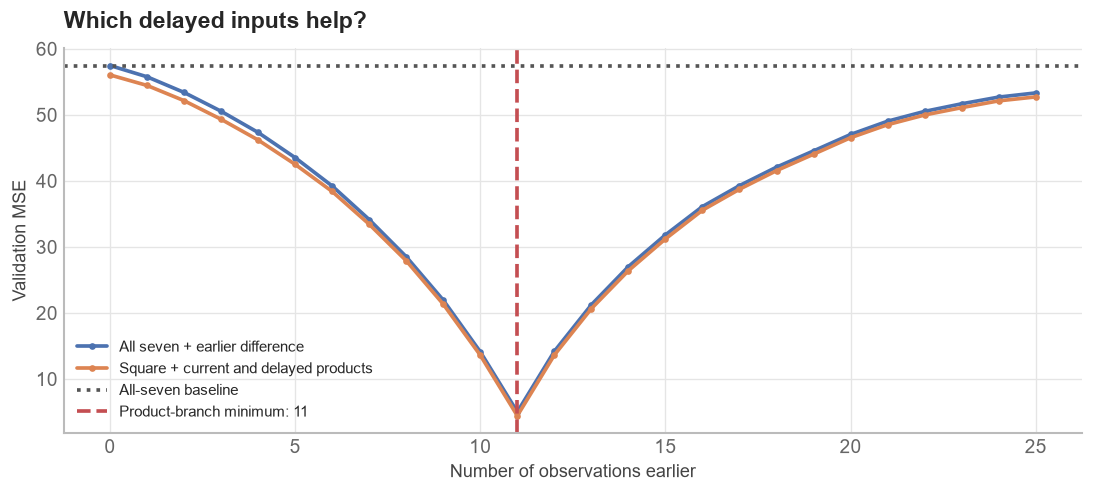

All seven + earlier difference: train MSE = 20.565, validation MSE = 5.008
Square + current and delayed products: train MSE = 17.372, validation MSE = 4.439
Selected product-branch delay: 11


In [18]:
lag_values = np.arange(max_lag + 1)
lag_errors, linear_lag_errors = [], []
for lag in lag_values:
    X_candidate = make_inputs(int(lag))
    assert np.isfinite(X_candidate[np.concatenate([train_rows, valid_rows])]).all()
    linear = FeatureRegression([delayed_difference(ratio_35)])
    products = FeatureRegression([square_term, interaction_term, delayed_interactions(ratio_35)])
    for candidate, errors in [(linear, linear_lag_errors), (products, lag_errors)]:
        candidate.fit(X_candidate[train_rows], y[train_rows])
        errors.append(float(mse(y[valid_rows], candidate.predict(X_candidate[valid_rows]))))

best_lag = int(lag_values[np.argmin(lag_errors)])
best_linear_lag = int(lag_values[np.argmin(linear_lag_errors)])
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(lag_values, linear_lag_errors, marker="o", ms=3, label="All seven + earlier difference")
ax.plot(lag_values, lag_errors, marker="o", ms=3, label="Square + current and delayed products")
ax.axhline(results[3]["Validation MSE"], color="#555555", ls=":", label="All-seven baseline")
ax.axvline(best_lag, color=palette[3], ls="--", label=f"Product-branch minimum: {best_lag}")
ax.set(xlabel="Number of observations earlier", ylabel="Validation MSE", title="Which delayed inputs help?")
ax.legend(fontsize=9)
plt.show()
if best_lag in (0, max_lag):
    print("The product-branch minimum is at a search boundary; revisit the delay range.")
m_linear_lag = evaluate("All seven + earlier difference", FeatureRegression([
    delayed_difference(ratio_35)]), make_inputs(best_linear_lag))
X_best = make_inputs(best_lag)
lag_term = delayed_interactions(ratio_35)
m_lag = evaluate("Square + current and delayed products", FeatureRegression([
    square_term, interaction_term, lag_term]), X_best)
print(f"Selected product-branch delay: {best_lag}")

The validation curves tell us whether earlier values help these particular models, and whether the products add more than an earlier difference alone. They do not establish a physical delay or a causal relationship. We are selecting a model for this ordered prediction task.

I would now return to the training residuals of the product branch. We have removed some of the larger variation, which can make smaller relationships easier to see. I will plot them against both differences, rather than looking only at the one that eventually suggests a useful addition.

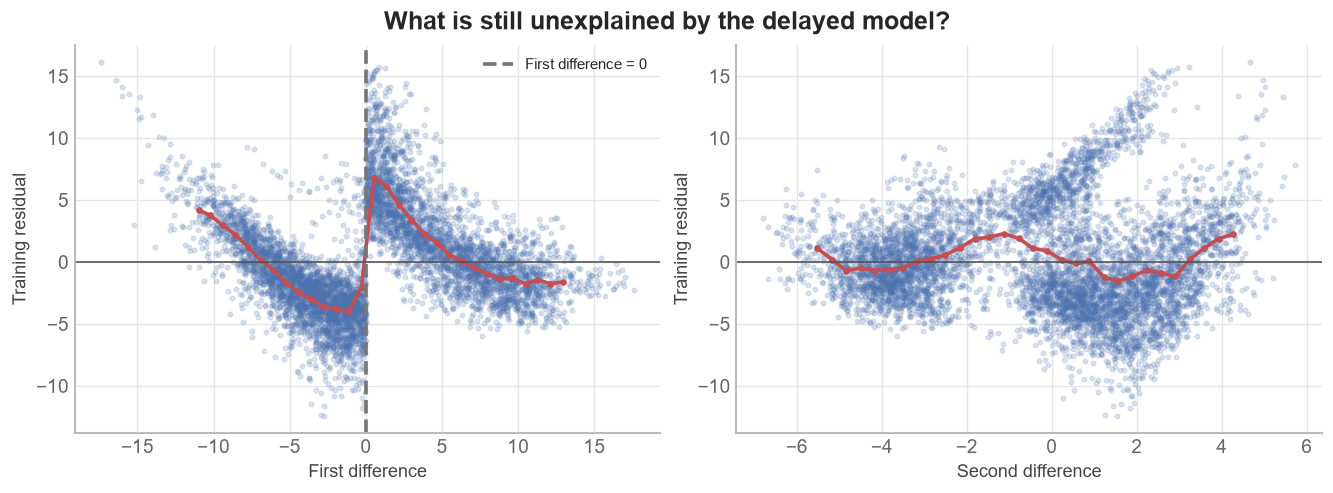

In [19]:
train_residual = training_residuals(m_lag, X_best)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, difference, label in zip(axes, [d12_train, d35_train], ["First difference", "Second difference"]):
    ax.scatter(difference, train_residual, alpha=0.18, s=7, rasterized=True)
    bx, by, _ = binned_means(difference, train_residual, n_bins=30)
    ax.plot(bx, by, color=palette[3], marker="o", ms=3)
    ax.axhline(0, color="#555555", lw=1)
    ax.set(xlabel=label, ylabel="Training residual")
axes[0].axvline(0, color="#777777", ls="--", label="First difference = 0")
axes[0].legend(fontsize=9)
fig.suptitle("What is still unexplained by the delayed model?", fontweight="bold")
plt.show()

### **7 - Does a relationship change across regions?**

In the first-difference plot, I would look closely at the change near zero. The observations immediately on either side appear to follow different residual patterns. This gives us a reason to try a split near zero, rather than choosing that threshold without looking at the residuals. It is an approximate boundary in this reference coordinate, not a known property of the problem.

I would first ask whether the two regions need different intercepts. Then I would look at the residuals against every original feature, coloured by region. This gives us a way to investigate a changing slope without selecting `x_7` in advance.

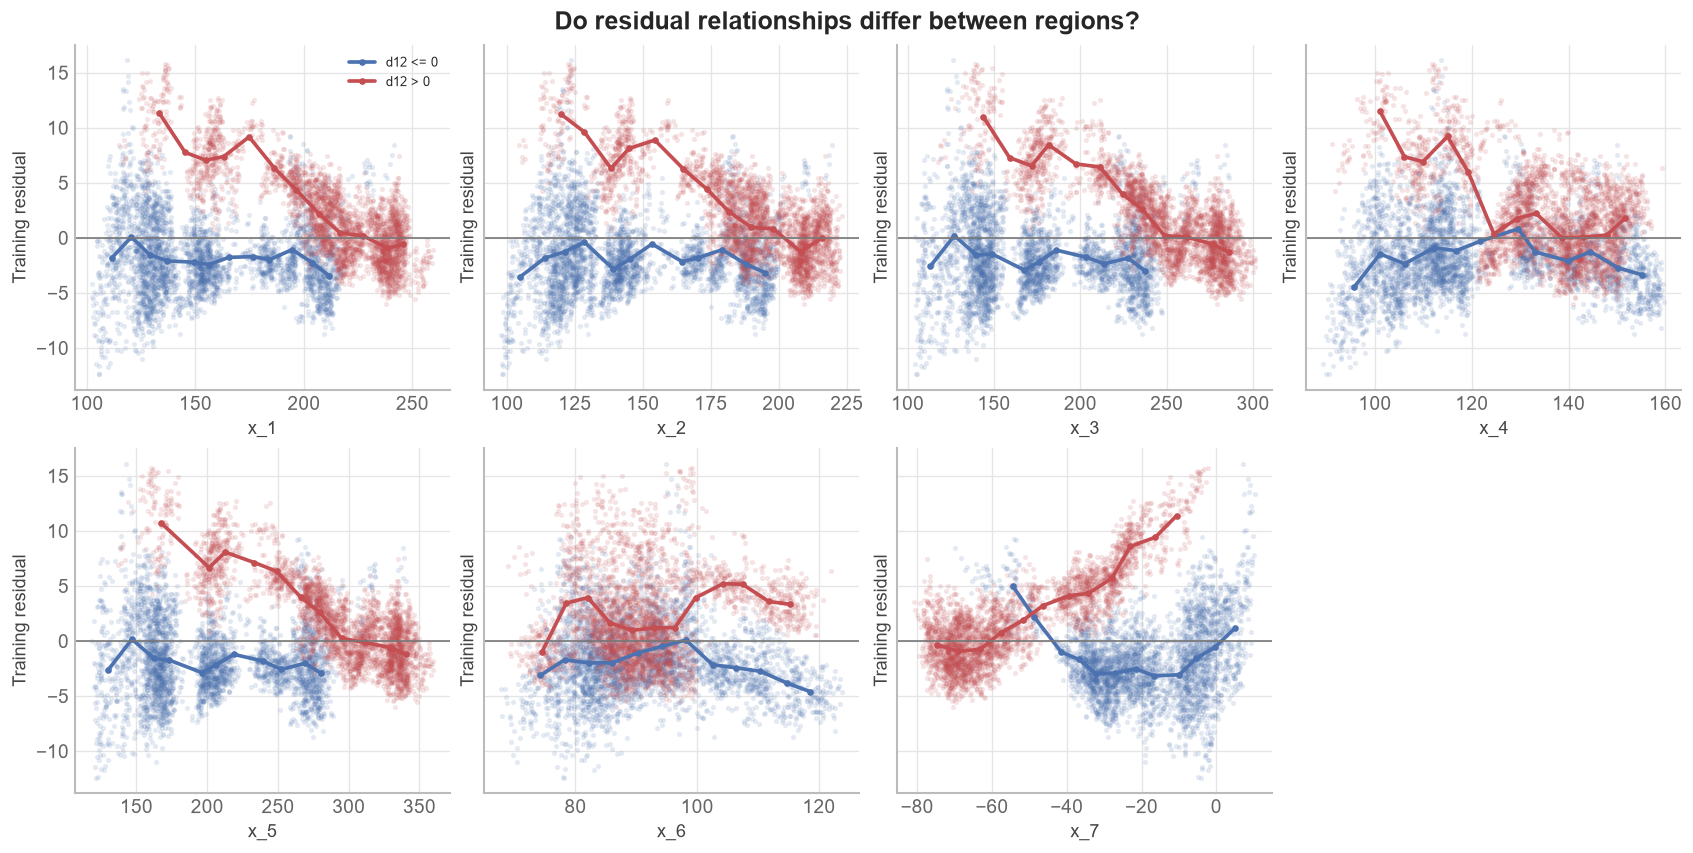

,Feature,Slope: d12 <= 0,Slope: d12 > 0
0,x_1,-0.007,-0.105
1,x_2,-0.001,-0.118
2,x_3,-0.003,-0.082
3,x_4,-0.003,-0.162
4,x_5,-0.003,-0.067
5,x_6,-0.019,0.053
6,x_7,0.023,0.175


In [20]:
positive = d12_train > 0
fig, axes = plt.subplots(2, 4, figsize=(14, 7), sharey=True)
slope_rows = []
for ax, feature in zip(axes.flat, features):
    slopes = []
    for group, label, colour in [(False, "d12 <= 0", palette[0]), (True, "d12 > 0", palette[3])]:
        mask = positive == group
        values = train[feature].to_numpy()[mask]
        res = train_residual[mask]
        ax.scatter(values, res, color=colour, s=5, alpha=0.10, rasterized=True)
        bx, by, _ = binned_means(values, res, n_bins=12)
        ax.plot(bx, by, color=colour, marker="o", ms=3, label=label)
        slopes.append(float(np.polyfit(values, res, 1)[0]))
    ax.axhline(0, color="#777777", lw=1)
    ax.set(xlabel=feature, ylabel="Training residual")
    slope_rows.append({"Feature": feature, "Slope: d12 <= 0": slopes[0], "Slope: d12 > 0": slopes[1]})
axes.flat[0].legend(fontsize=8)
axes.flat[-1].axis("off")
fig.suptitle("Do residual relationships differ between regions?", fontweight="bold")
plt.show()
display(pd.DataFrame(slope_rows).round(3))

The regional plots give us several possible experiments. I would include `x_7` because its positive-region trend is easier to see after this split than in the original target plot. However, I would not assume it is the only useful candidate, or interpret these simple residual slopes as isolated effects of the features.

Below I compare an indicator alone, and then the indicator with a separate slope for each original feature in turn. The indicator allows the intercept to change; multiplying it by a centred feature allows that feature's coefficient to change as well. The validation table makes the choice of a conditional feature explicit. We will still need to revisit this comparison after checking the difference scales.

In [21]:
x7_centre = float(train["x_7"].mean())
feature_centres = train[features].mean().to_numpy()

def region_terms(scale, column=None, threshold=0.0):
    centre = None if column is None else float(feature_centres[column])
    def indicator(X):
        return ((X[:, 0] - scale * X[:, 1]) > threshold).astype(float)
    terms = [indicator]
    if column is not None:
        def varying_slope(X):
            return indicator(X) * (X[:, column] - centre)
        terms.append(varying_slope)
    return terms

branch_terms = [square_term, interaction_term, lag_term]
region_comparisons = []
for column in [None, *range(7)]:
    name = "Delayed branch + indicator" if column is None else f"Delayed branch + conditional {features[column]}"
    candidate = evaluate(name, FeatureRegression(branch_terms + region_terms(ratio_12, column)), X_best)
    region_comparisons.append(results[-1])
    if column == 6:
        m_regime = candidate
display(pd.DataFrame(region_comparisons).sort_values("Validation MSE").round(3))

Delayed branch + indicator: train MSE = 6.405, validation MSE = 7.929
Delayed branch + conditional x_1: train MSE = 3.521, validation MSE = 2.027
Delayed branch + conditional x_2: train MSE = 3.577, validation MSE = 2.076
Delayed branch + conditional x_3: train MSE = 3.158, validation MSE = 1.713
Delayed branch + conditional x_4: train MSE = 5.022, validation MSE = 4.056
Delayed branch + conditional x_5: train MSE = 3.077, validation MSE = 1.689
Delayed branch + conditional x_6: train MSE = 6.352, validation MSE = 7.552
Delayed branch + conditional x_7: train MSE = 2.431, validation MSE = 2.254


,Model,Train MSE,Validation MSE
5,Delayed branch + conditional x_5,3.077,1.689
3,Delayed branch + conditional x_3,3.158,1.713
1,Delayed branch + conditional x_1,3.521,2.027
2,Delayed branch + conditional x_2,3.577,2.076
7,Delayed branch + conditional x_7,2.431,2.254
4,Delayed branch + conditional x_4,5.022,4.056
6,Delayed branch + conditional x_6,6.352,7.552
0,Delayed branch + indicator,6.405,7.929


### **8 - Checking the difference scales and earlier additions**

Our initial scales came from the input means, which does not necessarily make them useful for predicting the target. This matters more once we square a difference, multiply it by another input, or use it to define a region. For example, $(x_3-cx_5)x_4$ ties the coefficients of $x_3x_4$ and $x_5x_4$ together through $c$. We could instead fit those products separately, but here I will first investigate the simpler shared-scale model.

I will search within 0.05 of each initial scale, in steps of 0.01. This is an explicit local sensitivity check around our training-derived references. The span and step are practical choices, not quantities inferred from the plots. A minimum at an edge would mean we should expand the range.

I will repeat the same search with and without the square, and with no region term, an indicator alone, or a conditional slope for each original feature. This lets us revisit the earlier failures under the same tuning conditions, rather than attributing an improvement to whichever addition happened to come before it. The delay is held fixed for this comparison.

,Square,Region,c12,c35,Validation MSE
2115,True,x_7,1.10,0.83,0.1205
1874,True,x_5,1.10,0.84,0.6756
1632,True,x_3,1.10,0.84,0.7205
1389,True,x_1,1.10,0.83,0.8064
1510,True,x_2,1.10,0.83,0.8608
1037,False,x_7,1.11,0.83,0.9851
322,False,x_1,1.12,0.83,1.0203
806,False,x_5,1.12,0.83,1.0549
564,False,x_3,1.12,0.83,1.0912
443,False,x_2,1.12,0.83,1.1269


Tuned: square=False, region=indicator: train MSE = 12.440, validation MSE = 1.418
Tuned: square=False, region=none: train MSE = 15.391, validation MSE = 2.063
Tuned: square=False, region=x_1: train MSE = 13.775, validation MSE = 1.020
Tuned: square=False, region=x_2: train MSE = 13.849, validation MSE = 1.127
Tuned: square=False, region=x_3: train MSE = 13.772, validation MSE = 1.091
Tuned: square=False, region=x_4: train MSE = 11.888, validation MSE = 1.271
Tuned: square=False, region=x_5: train MSE = 13.744, validation MSE = 1.055
Tuned: square=False, region=x_6: train MSE = 12.324, validation MSE = 1.381
Tuned: square=False, region=x_7: train MSE = 10.816, validation MSE = 0.985
Tuned: square=True, region=indicator: train MSE = 11.709, validation MSE = 1.660
Tuned: square=True, region=none: train MSE = 15.390, validation MSE = 2.128
Tuned: square=True, region=x_1: train MSE = 1.385, validation MSE = 0.806
Tuned: square=True, region=x_2: train MSE = 1.439, validation MSE = 0.861
Tune

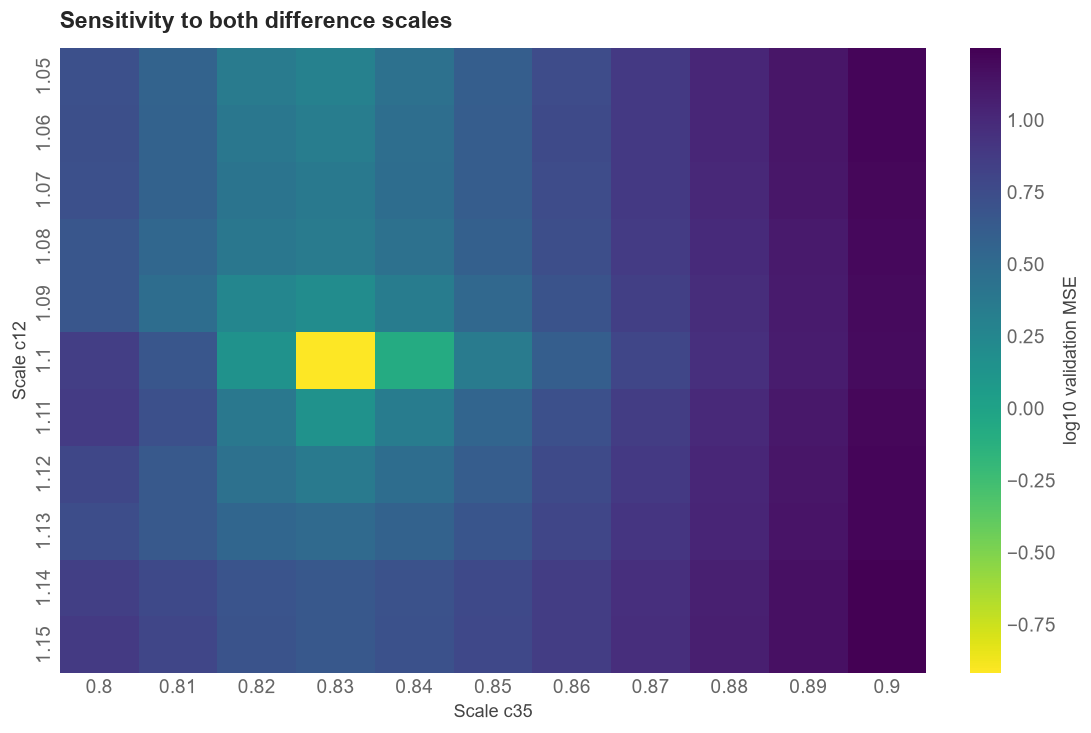

In [22]:
# Consolidate only the additions that we have already investigated.
def build_terms(c12, c35, *, square=True, interactions=True,
                lag_interactions=True, region="none"):
    terms = []
    if square:
        terms.append(squared_difference(c12))
    if interactions:
        terms.append(current_interactions(c35))
    if lag_interactions:
        terms.append(delayed_interactions(c35))
    if region != "none":
        column = None if region == "indicator" else features.index(region)
        terms.extend(region_terms(c12, column))
    return terms

ratio12_candidates = np.round(initial_ratio_12 + np.arange(-5, 6) * 0.01, 3)
ratio_candidates = np.round(initial_ratio_35 + np.arange(-5, 6) * 0.01, 3)
scale_search = []
for square in [False, True]:
    for region in ["none", "indicator", *features]:
        for c12 in ratio12_candidates:
            for c35 in ratio_candidates:
                candidate = FeatureRegression(build_terms(float(c12), float(c35), square=square, region=region))
                candidate.fit(X_best[train_rows], y[train_rows])
                error = float(mse(y[valid_rows], candidate.predict(X_best[valid_rows])))
                scale_search.append({"Square": square, "Region": region,
                                     "c12": float(c12), "c35": float(c35), "Validation MSE": error})
scale_search = pd.DataFrame(scale_search)
branch_winners = scale_search.loc[scale_search.groupby(["Square", "Region"])["Validation MSE"].idxmin()]
display(branch_winners.sort_values("Validation MSE").round(4))
chosen = scale_search.loc[scale_search["Validation MSE"].idxmin()]
ratio_12, ratio_35 = float(chosen["c12"]), float(chosen["c35"])
chosen_square, chosen_region = bool(chosen["Square"]), str(chosen["Region"])
for _, row in branch_winners.iterrows():
    evaluate(f"Tuned: square={bool(row['Square'])}, region={row['Region']}",
             FeatureRegression(build_terms(float(row["c12"]), float(row["c35"]),
                                           square=bool(row["Square"]), region=str(row["Region"]))), X_best)
tuned_terms = build_terms(ratio_12, ratio_35, square=chosen_square, region=chosen_region)
m_tuned = evaluate("Selected tuned branch", FeatureRegression(tuned_terms), X_best)
print(f"Selected scales: c12={ratio_12:.3f}, c35={ratio_35:.3f}; "
      f"square={chosen_square}, region={chosen_region}")
for value, grid, label in [(ratio_12, ratio12_candidates, "c12"), (ratio_35, ratio_candidates, "c35")]:
    if value in (grid[0], grid[-1]):
        print(f"Selected {label} is at a boundary: expand the range before interpreting it.")

chosen_branch = scale_search[(scale_search["Square"] == chosen_square) & (scale_search["Region"] == chosen_region)]
surface = chosen_branch.pivot(index="c12", columns="c35", values="Validation MSE")
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(np.log10(surface), cmap="viridis_r", ax=ax,
            cbar_kws={"label": "log10 validation MSE"})
ax.set(xlabel="Scale c35", ylabel="Scale c12", title="Sensitivity to both difference scales")
plt.show()
# A one-dimensional slice is also available for the chart-data exporter.
ratio_errors = chosen_branch[chosen_branch["c12"] == ratio_12].sort_values("c35")["Validation MSE"].tolist()

This table compares each branch after giving it the same local scale search. I would use it to decide whether the square, the indicator, and a changing slope have earned a place together. The scales and the selected feature are modelling choices supported by validation results, rather than recovered constants from the original data-generating process.

We have now tried quite a few choices on one validation block. That makes its best error an optimistic guide to future performance. For a larger project I would repeat the comparisons across several ordered validation blocks. Here we will finish this walkthrough with one final test, while keeping that limitation in mind.

I will now inspect the training residuals of the selected tuned branch against the first difference again. I use 60 equal-width bins over its central 98% and require at least 20 observations per bin. Those are plotting choices to reduce clutter; the scatterplot remains alongside the means so we can see what the grouping hides.

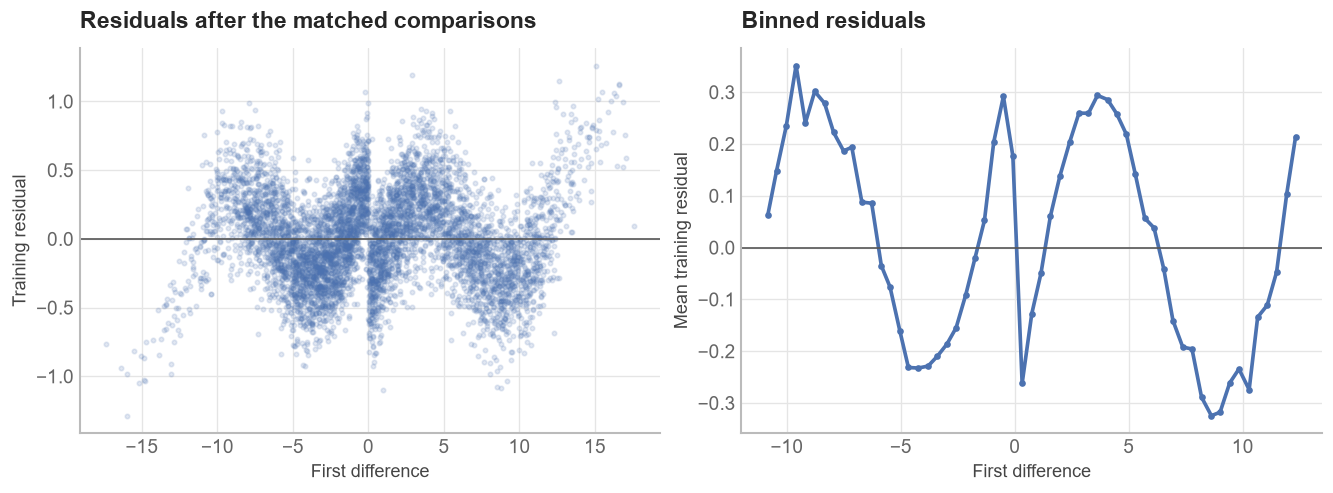

In [23]:
d12 = data["x_1"] - ratio_12 * data["x_2"]
d12_train = d12.iloc[train_rows].to_numpy()
residual = training_residuals(m_tuned, X_best)
centres, averages, bin_counts = binned_means(d12_train, residual, n_bins=60)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(d12_train, residual, s=7, alpha=0.16, rasterized=True)
axes[0].set(xlabel="First difference", ylabel="Training residual", title="Residuals after the matched comparisons")
axes[1].plot(centres, averages, marker="o", ms=3)
axes[1].set(xlabel="First difference", ylabel="Mean training residual", title="Binned residuals")
for ax in axes:
    ax.axhline(0, color="#555555", lw=1)
plt.show()

### **9 - Looking at the remaining pattern**

The binned residuals give us a way to look for a small repeating pattern. If a similar shape repeats over the first difference, a periodic basis is worth testing. A sine alone would fix the phase relative to zero, for which we have no particular reason. I will therefore add both sine and cosine at the same frequency, allowing their fitted coefficients to choose the phase.

To choose an initial search range, I will estimate the strongest repeating frequency in the binned training residuals. The calculation below uses a Fourier transform of equally spaced bin means, after removing a straight-line trend. This is a rough diagnostic: the bins cover a limited range, and grouping and other unmodelled patterns can affect the estimate. It gives us a starting range to test, rather than a frequency to accept without comparison.

I will search from half to one-and-a-half times that estimate, then refine around the best validation frequency. I will keep the periodic pair only if validation performance supports it. I would also check whether the apparent pattern is stable across training periods before relying on it in a larger project.

Rough training-residual period: 12.43 difference units
Rough angular frequency: 0.506 radians per difference unit


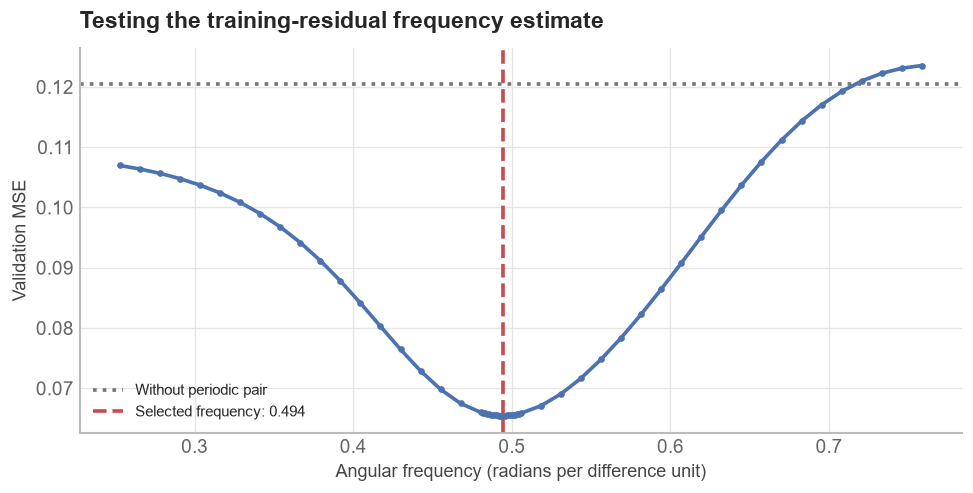

Tuned branch + sine and cosine: train MSE = 0.062, validation MSE = 0.065


In [24]:
# Equal-width bins are needed for this rough spectral estimate.
edges = np.linspace(*np.percentile(d12_train, [1, 99]), 61)
midpoints = (edges[:-1] + edges[1:]) / 2
groups = np.digitize(d12_train, edges)
bin_signal = np.array([residual[groups == j].mean() if (groups == j).sum() >= 20 else np.nan
                       for j in range(1, len(edges))])
occupied = np.isfinite(bin_signal)
assert occupied.sum() >= 10
# Interpolate gaps for the diagnostic only; fitting always uses individual rows.
bin_signal = np.interp(midpoints, midpoints[occupied], bin_signal[occupied])
trend = np.polyval(np.polyfit(midpoints, bin_signal, 1), midpoints)
power = np.abs(np.fft.rfft((bin_signal - trend) * np.hanning(len(bin_signal)))) ** 2
omega = 2 * np.pi * np.fft.rfftfreq(len(bin_signal), d=edges[1] - edges[0])
peak = 1 + int(np.argmax(power[1:]))
initial_frequency = float(omega[peak])
print(f"Rough training-residual period: {2 * np.pi / initial_frequency:.2f} difference units")
print(f"Rough angular frequency: {initial_frequency:.3f} radians per difference unit")

def periodic_terms(scale, frequency):
    def term(X):
        difference = X[:, 0] - scale * X[:, 1]
        return np.column_stack([np.sin(frequency * difference), np.cos(frequency * difference)])
    return term

def frequency_error(frequency):
    candidate = FeatureRegression(tuned_terms + [periodic_terms(ratio_12, float(frequency))])
    candidate.fit(X_best[train_rows], y[train_rows])
    return float(mse(y[valid_rows], candidate.predict(X_best[valid_rows])))

coarse_frequencies = np.linspace(0.5 * initial_frequency, 1.5 * initial_frequency, 41)
coarse_errors = [frequency_error(freq) for freq in coarse_frequencies]
coarse_best = int(np.argmin(coarse_errors))
if coarse_best in (0, len(coarse_frequencies) - 1):
    print("The coarse frequency minimum is at a boundary; revisit the frequency range.")
lo = coarse_frequencies[max(0, coarse_best - 1)]
hi = coarse_frequencies[min(len(coarse_frequencies) - 1, coarse_best + 1)]
frequencies = np.unique(np.concatenate([coarse_frequencies, np.linspace(lo, hi, 21)]))
frequency_errors = [frequency_error(freq) for freq in frequencies]
best_frequency = float(frequencies[np.argmin(frequency_errors)])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(frequencies, frequency_errors, marker="o", ms=3)
ax.axhline(mse(y[valid_rows], m_tuned.predict(X_best[valid_rows])), color="#777777", ls=":", label="Without periodic pair")
ax.axvline(best_frequency, color=palette[3], ls="--", label=f"Selected frequency: {best_frequency:.3f}")
ax.set(xlabel="Angular frequency (radians per difference unit)", ylabel="Validation MSE",
       title="Testing the training-residual frequency estimate")
ax.legend(fontsize=9)
plt.show()
m_periodic = evaluate("Tuned branch + sine and cosine", FeatureRegression(
    tuned_terms + [periodic_terms(ratio_12, best_frequency)]), X_best)

### **10 - Checking what each retained addition contributes**

Before selecting the final model, I would remove each group of extra terms in turn and refit the coefficients. The scales, delay, conditional feature, and frequency stay fixed for these comparisons. This tells us whether an addition helps in the current combination; it is different from its first experiment earlier in the notebook.

These are comparisons at the selected settings, rather than a fresh search for the best possible version of every smaller model. The earlier scale table already gave each square-and-region branch its own local search. If removing a term improves validation performance here, that smaller candidate will also be eligible for final selection.

In [25]:
ablation_rows = [{"Removed": "Nothing", "Validation MSE": float(mse(y[valid_rows], m_periodic.predict(X_best[valid_rows])))}]
for removed in ["square", "current products", "delayed products", "region", "periodic pair"]:
    if removed == "square" and not chosen_square:
        continue
    if removed == "region" and chosen_region == "none":
        continue
    terms = build_terms(ratio_12, ratio_35,
                        square=chosen_square and removed != "square",
                        interactions=removed != "current products",
                        lag_interactions=removed != "delayed products",
                        region="none" if removed == "region" else chosen_region)
    if removed != "periodic pair":
        terms.append(periodic_terms(ratio_12, best_frequency))
    evaluate(f"Final comparison: without {removed}", FeatureRegression(terms), X_best)
    ablation_rows.append({"Removed": removed, "Validation MSE": results[-1]["Validation MSE"]})
display(pd.DataFrame(ablation_rows).sort_values("Validation MSE").round(5))

Final comparison: without square: train MSE = 1.922, validation MSE = 1.863
Final comparison: without current products: train MSE = 0.324, validation MSE = 0.249
Final comparison: without delayed products: train MSE = 39.162, validation MSE = 56.140
Final comparison: without region: train MSE = 8.969, validation MSE = 3.674
Final comparison: without periodic pair: train MSE = 0.110, validation MSE = 0.121


,Removed,Validation MSE
0,Nothing,0.06547
5,periodic pair,0.12053
2,current products,0.24901
1,square,1.86261
4,region,3.67424
3,delayed products,56.13971


### **11 - Comparing the models and checking generalisation**

Here I would look back over the validation results from each stage. We now have comparisons for simple models, nonlinear inputs, delays, regional effects, scale choices, and the periodic pair. Some ideas can help together even when they did not help at their first settings. Other additions may still be unnecessary. The tables let us distinguish those cases without relying on the order in which we tried things.

I will select the candidate with the lowest recorded validation error, rather than assuming the last or most complicated model is best. Then I will refit its coefficients and normalisation on training and validation together. Its feature functions and other choices remain fixed. This is the first point at which we will calculate predictions and errors using the reserved test targets.

,Model,Train MSE,Validation MSE
38,Tuned branch + sine and cosine,0.06220,0.06547
43,Final comparison: without periodic pair,0.11021,0.12053
36,"Tuned: square=True, region=x_7",0.11021,0.12053
37,Selected tuned branch,0.11021,0.12053
40,Final comparison: without current products,0.32403,0.24901
34,"Tuned: square=True, region=x_5",1.77176,0.67562
32,"Tuned: square=True, region=x_3",1.87110,0.72053
30,"Tuned: square=True, region=x_1",1.38478,0.80635
31,"Tuned: square=True, region=x_2",1.43873,0.86077
27,"Tuned: square=False, region=x_7",10.81645,0.98506


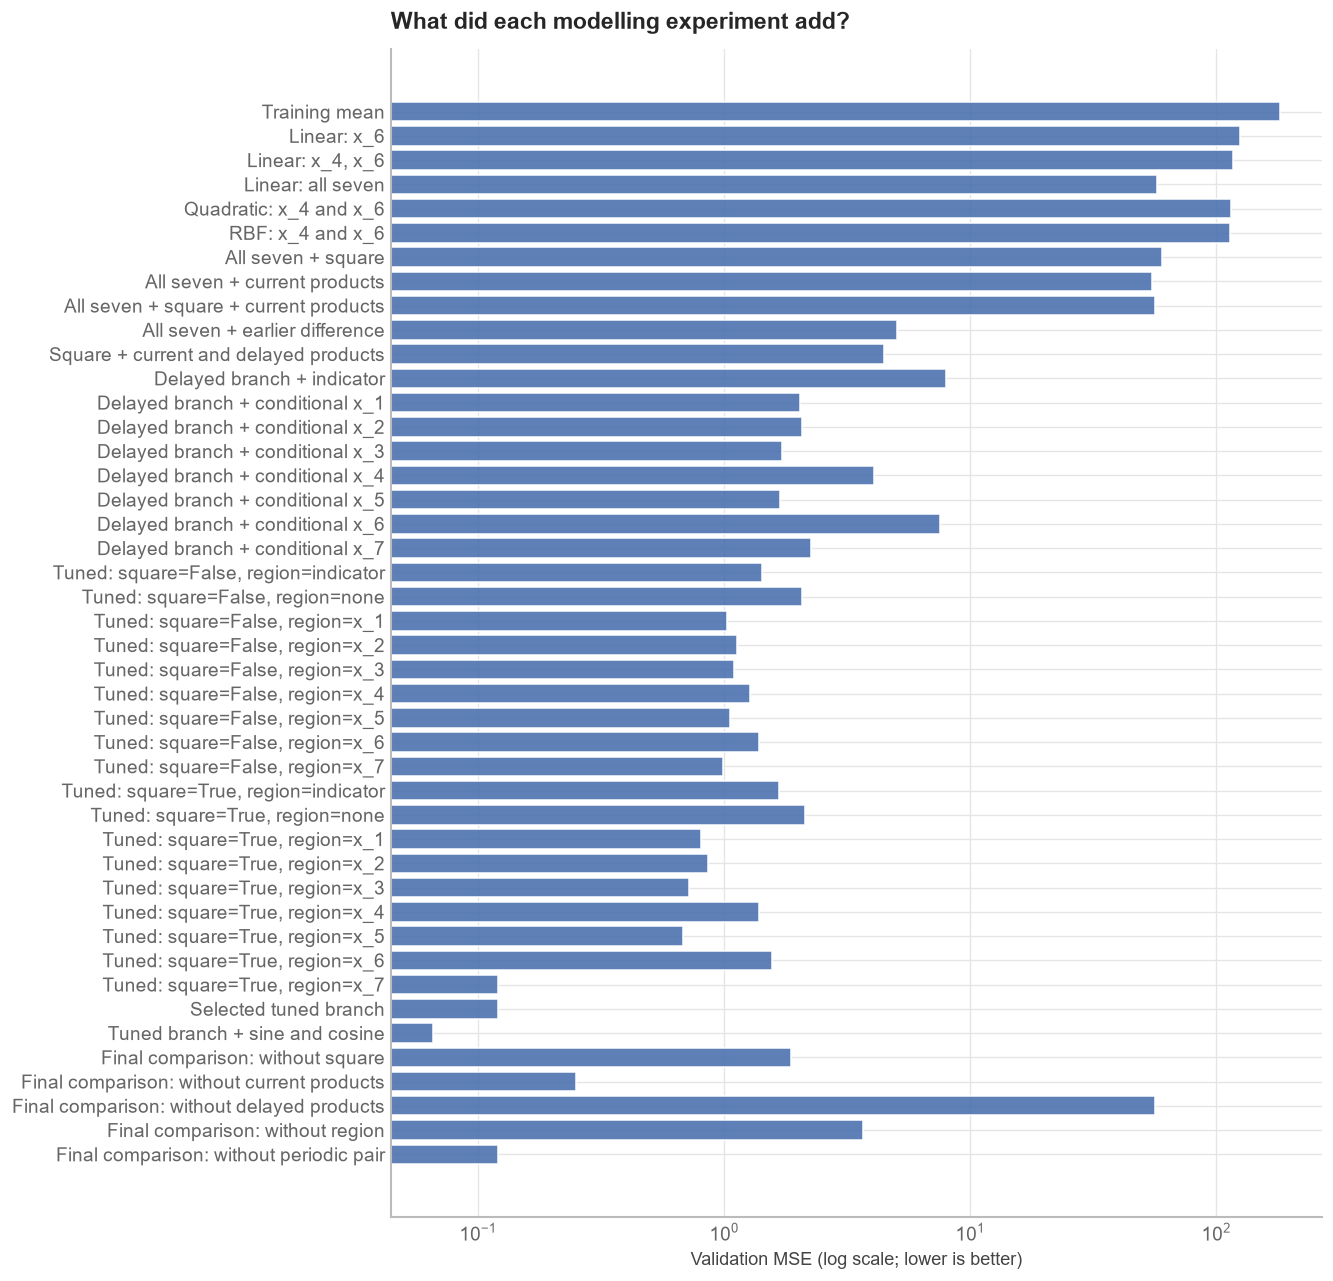

Selected using validation error: Tuned branch + sine and cosine


In [26]:
summary = pd.DataFrame(results)
display(summary.sort_values("Validation MSE").round(5))
fig, ax = plt.subplots(figsize=(11, max(6, 0.24 * len(summary))))
ax.barh(summary["Model"], summary["Validation MSE"], color=palette[0], alpha=0.9)
ax.invert_yaxis()
ax.set_xscale("log")
ax.set(xlabel="Validation MSE (log scale; lower is better)", title="What did each modelling experiment add?")
plt.show()
selected_name = str(summary.loc[summary["Validation MSE"].idxmin(), "Model"])
print(f"Selected using validation error: {selected_name}")

Test MSE: 0.0602
Test R^2: 0.99970


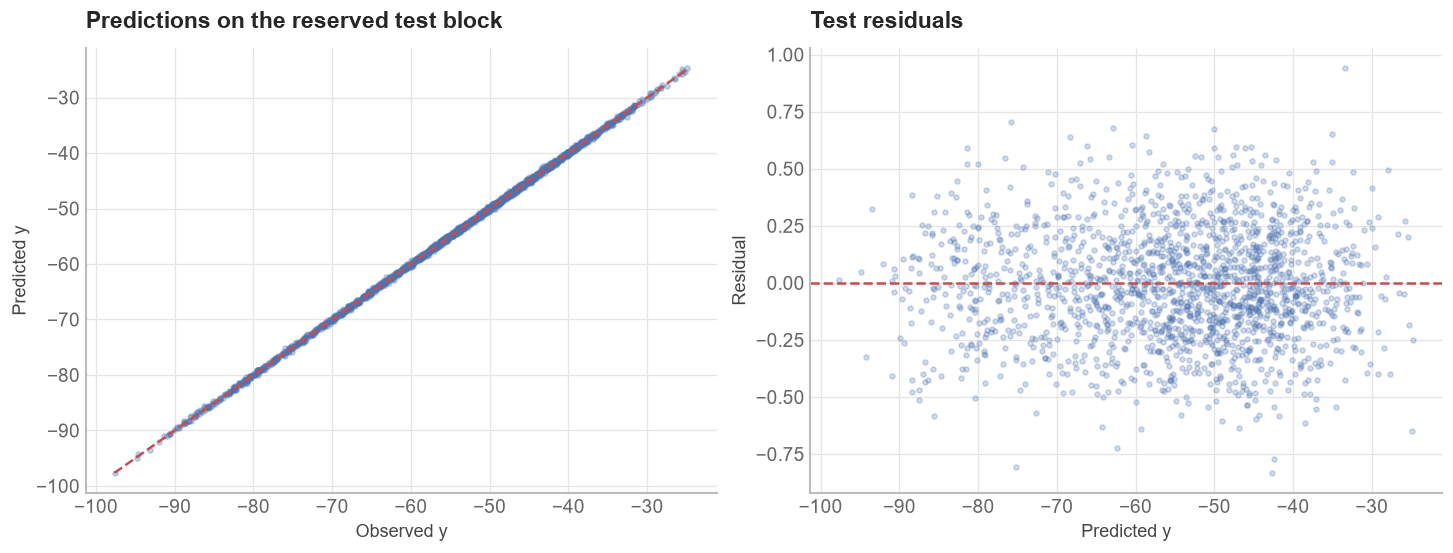

In [27]:
from copy import deepcopy

selected_model, selected_inputs = fitted_models[selected_name]
final_model = deepcopy(selected_model)
train_valid_rows = np.concatenate([train_rows, valid_rows])
final_model.fit(selected_inputs[train_valid_rows], y[train_valid_rows])
test_pred = final_model.predict(selected_inputs[test_rows])
final_mse = float(mse(y[test_rows], test_pred))
final_r2 = float(1 - np.sum((test_pred - y[test_rows]) ** 2)
                 / np.sum((y[test_rows] - y[test_rows].mean()) ** 2))
print(f"Test MSE: {final_mse:.4f}")
print(f"Test R^2: {final_r2:.5f}")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y[test_rows], test_pred, alpha=0.3, s=9, rasterized=True)
lo = min(y[test_rows].min(), test_pred.min())
hi = max(y[test_rows].max(), test_pred.max())
axes[0].plot([lo, hi], [lo, hi], c=palette[3], ls="--", lw=1.5)
axes[0].set(xlabel="Observed y", ylabel="Predicted y", title="Predictions on the reserved test block")
axes[1].scatter(test_pred, y[test_rows] - test_pred, alpha=0.25, s=9, rasterized=True)
axes[1].axhline(0, c=palette[3], ls="--", lw=1.5)
axes[1].set(xlabel="Predicted y", ylabel="Residual", title="Test residuals")
plt.show()

### **12 - What I would like you to take away from this**

What I would like you to take away from this walkthrough is the process of looking at the data, drawing conclusions, and using those conclusions to decide what to try next. I would not expect you to have guessed these particular basis functions.

The original scatterplots gave us a starting point, however, they did not show all the useful relationships. Looking at the features together and plotting them against the row index gave us other ideas to investigate. Later, looking at the residuals helped us find relationships that were harder to see at the beginning.

For each change, I would like you to be able to point to the observation that led you to try it, explain the relationship it allows the model to express, and show a fair validation comparison. When a numerical choice is just a starting budget or a plotting choice, say so. When an addition fails, use that result rather than quietly carrying it forward as though it succeeded.

One other thing to keep in mind is that the model remained linear in its fitted coefficients throughout. We changed the functions of the inputs in the design matrix, and selected some of their settings using validation data, but we could still fit the coefficients using least squares.

This does not prove that we have found the equation used to generate the data. We have compared a collection of hypotheses, selected one using a repeatedly consulted validation block, and checked it on a reserved later block. Its usefulness still depends on whether that prediction task matches the original problem. If I were marking this practical, that reasoning would matter at least as much as the final MSE.